## **Combined Training:**

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
%load_ext autoreload
%autoreload 3

In [3]:
# Import all python library packages
from lib_imports import *

I0000 00:00:1786263659.205089 3810855 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1786263659.250506 3810855 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1786263660.972321 3810855 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [5]:
print("=" * 50)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA version:", torch.version.cuda)
    print("CUDA device count:", torch.cuda.device_count())
    print("Current GPU:", torch.cuda.get_device_name(0))
    print("cuDNN version:", torch.backends.cudnn.version())
print()
print("ONNXRuntime version:", ort.__version__)
print("ONNX providers:", ort.get_available_providers())
print("=" * 50)

# Automatic device detection
RUNTIME_MODE = "auto"        # Options: "auto", "cpu", "gpu", "mps"

# auto — pick the best available device
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")                 # NVIDIA GPU
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")                  # Apple Silicon GPU
else:
    DEVICE = torch.device("cpu")                  # Fallback to CPU

# Print device name
print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print("Device name:", torch.cuda.get_device_name(0))
elif DEVICE.type == "mps":
    print("Device name: Apple Silicon GPU (MPS)")
else:
    print("Device name: CPU")

PyTorch version: 2.5.1+cu121
CUDA available: True
CUDA version: 12.1
CUDA device count: 1
Current GPU: NVIDIA H100 NVL
cuDNN version: 90100

ONNXRuntime version: 1.26.0
ONNX providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Using device: cuda
Device name: NVIDIA H100 NVL


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

In [6]:
#========================================================
# Reproducibility Setup
#========================================================

# Function to control randomness across libraries
def set_seed(seed):                                          
    random.seed(seed)                               # Fix Python random numbers
    np.random.seed(seed)                            # Fix NumPy random numbers
    torch.manual_seed(seed)                         # Fix PyTorch CPU random numbers
    torch.cuda.manual_seed_all(seed)                # Fix PyTorch GPU random numbers
    torch.backends.cudnn.deterministic = True       # Ensure deterministic GPU operations (Forces same operations every time)
    torch.backends.cudnn.benchmark = False          # Disable auto-optimisation for consistent results (Stops CUDA from picking fastest algorithms, which can be random)
    print(f"Seeding applied: SEED={SEED}")

SEED = 42  # Set a fixed seed value for reproducibility
set_seed(SEED)

Seeding applied: SEED=42


In [7]:
# ============================================================================
#  STEP 0 - Provide configuration paths
# ============================================================================

# ============================================================================
#  SiW
# ============================================================================
# Paths (where data and outputs are stored)
DATA_ROOT_SiW   = Path('./DATA/SiW-Mv2')                                                           # Main dataset folder
REAL_DIR_SiW    = DATA_ROOT_SiW / 'Live'                                                           # Folder for real videos
ATTACK_DIRS_SiW = {                                                                                # Attack folders collected in a set
    'makeup_cosmetic'         :   DATA_ROOT_SiW / 'Spoof' / 'Makeup_Cosmetic',
    'makeup_impersonation'    :   DATA_ROOT_SiW / 'Spoof' / 'Makeup_Impersonation',
    'makeup_obfuscation'      :   DATA_ROOT_SiW / 'Spoof' / 'Makeup_Obfuscation',
    'mannequin'               :   DATA_ROOT_SiW / 'Spoof' / 'Mannequin',
    'mask_halfmask'           :   DATA_ROOT_SiW / 'Spoof' / 'Mask_HalfMask',
    'mask_papermask'          :   DATA_ROOT_SiW / 'Spoof' / 'Mask_PaperMask',
    'mask_transparentmask'    :   DATA_ROOT_SiW / 'Spoof' / 'Mask_TransparentMask',
    'paper'                   :   DATA_ROOT_SiW / 'Spoof' / 'Paper',
    'partial_eye'             :   DATA_ROOT_SiW / 'Spoof' / 'Partial_Eye',
    'partial_funnyeyeglasses' :   DATA_ROOT_SiW / 'Spoof' / 'Partial_FunnyeyeGlasses',
    'partial_mouth'           :   DATA_ROOT_SiW / 'Spoof' / 'Partial_Mouth',
    'partial_paperglasses'    :   DATA_ROOT_SiW / 'Spoof' / 'Partial_PaperGlasses',
    'replay'                  :   DATA_ROOT_SiW / 'Spoof' / 'Replay',
    'silicone'                :   DATA_ROOT_SiW / 'Spoof' / 'Silicone'       
}   


PROTOCOL_DIR_SiW = DATA_ROOT_SiW / 'subjects_split_info'

OUTPUT_ROOT_SiW = Path('./output_siW')                                                           # Main output folder
CACHE_DIR_SiW   = OUTPUT_ROOT_SiW / 'frame_cache'                                                # Store extracted frames
RESULT_DIR_SiW  = OUTPUT_ROOT_SiW / 'results'

TEST_DIR_SiW = Path('./test_siW_files')                                                          # Store testing files like checking landmarks etc midway

# Used by Protocol 2 (leave-one-attack-out). 'live' is the bona-fide class.
SPOOF_ATTACKS_SiW = list(ATTACK_DIRS_SiW.keys())
REAL_LABEL_SiW = 'live'   # the bona-fide / real class name


# PROTOCOL-SPECIFIC CONFIG
PROTOCOL_CONFIG_SiW = {
    # ---- Protocol I: Known Spoof Attack Detection -------------------
    1 : {
        'mode'             : 'known',
        'train_live_P1'    : PROTOCOL_DIR_SiW / 'trainlist_live.txt',
        'train_spoof_P1'   : PROTOCOL_DIR_SiW / 'trainlist_all.txt',
        'test_live_P1'     : PROTOCOL_DIR_SiW / 'testlist_live.txt',
        'test_spoof_P1'    : PROTOCOL_DIR_SiW / 'testlist_all.txt',
        'ckpt'             : RESULT_DIR_SiW / 'protocol_1' / 'best_model_protocol_1.pth',
        'result'           : RESULT_DIR_SiW / 'protocol_1',
    },
 
    # ---- Protocol II: Unknown Spoof Attack Detection ---------------
    2 : {
        'mode'                     : 'leave_one_attack_out',
        'train_live_P2_80per'      : PROTOCOL_DIR_SiW / 'trainlist_live.txt',
        'test_live_P2_20per'       : PROTOCOL_DIR_SiW / 'testlist_live.txt',
        'live_train_frac'          : 0.80,                                        # 80-20 split of live samples
        'ckpt_prefix'              : RESULT_DIR_SiW / 'protocol_2' / 'best_model_protocol_2_',     # + <attack>.pth
        'result'                   : RESULT_DIR_SiW / 'protocol_2',
    },
 
    # ---- Protocol III: Cross-domain Spoof Detection ----------------
    3 : {
        'mode'                        : 'cross_domain',
        'train_source_domain_A_P3'    : PROTOCOL_DIR_SiW / 'train_A_pretrain.txt',    # source domain for training
        'test_spoof_domain_B_P3'      : PROTOCOL_DIR_SiW / 'test_B_spoof.txt',        # target domain B subject for testing
        'test_race_domain_C_P3'       : PROTOCOL_DIR_SiW / 'test_C_race.txt',         # target domain C subject for testing
        'test_age_domain_D_P3'        : PROTOCOL_DIR_SiW / 'test_D_age.txt',          # target domain D subject for testing
        'test_illu_domain_E_P3'       : PROTOCOL_DIR_SiW / 'test_E_ill.txt',         # target domain E subject for testing
        'n_domains'                   : 5,
        'ckpt_prefix'                 : RESULT_DIR_SiW / 'protocol_3' / 'best_model_protocol_3_',  # + <domain>.pth
        'result'                      : RESULT_DIR_SiW / 'protocol_3',
    }
}
print('\nSiw configurations:')
print("Data Root:", DATA_ROOT_SiW)
print("Real:", REAL_DIR_SiW)
print("Attack:", ATTACK_DIRS_SiW)
print("Protocol:", PROTOCOL_DIR_SiW)
print("Cache:", CACHE_DIR_SiW)
print("Results (All):", RESULT_DIR_SiW)


# ============================================================================
#  OULU
# ============================================================================

# Configuration of OULU

# Paths (where data and outputs are stored)
DATA_ROOT_OULU   = Path('./DATA/OULU-NPU')                                                         # Main dataset folder
REAL_DIR_OULU    = DATA_ROOT_OULU / 'useful_splits' / 'real'                                       # Folder for real videos
ATTACK_DIRS_OULU = {                                                                               # Attack folders collected in a set
    'presentation'         :   DATA_ROOT_OULU / 'useful_splits' / 'presentation',
    'replay'               :   DATA_ROOT_OULU / 'useful_splits' / 'replay',      
}   
PROTOCOL_DIR_OULU = DATA_ROOT_OULU / 'Protocols'

OUTPUT_ROOT_OULU = Path('./output_OULU-NPU')                                                       # Main output folder
CACHE_DIR_OULU   = OUTPUT_ROOT_OULU / 'frame_cache'                                                # Store extracted frames
RESULT_DIR_OULU  = OUTPUT_ROOT_OULU / 'results'

TEST_DIR_OULU = Path('./test_output_OULU-NPU_files')                                               # Store testing files like checking landmarks etc midway

# Used by Protocol 3,4 (leave-one-attack-out). 'live' is the bona-fide class.
SPOOF_ATTACKS_OULU = list(ATTACK_DIRS_OULU.keys())
REAL_LABEL_OULU = 'live'   # the bona-fide / real class name


# PROTOCOL-SPECIFIC CONFIG
PROTOCOL_CONFIG_OULU = {

    # ---- Protocol I: Unseen environment -------------------
    1 : {
        'mode'             : 'unseen_environment',
        'train_P1'         : PROTOCOL_DIR_OULU / 'Protocol_1' / 'Train.txt',
        'dev_P1'           : PROTOCOL_DIR_OULU / 'Protocol_1' / 'Dev.txt',
        'test_P1'          : PROTOCOL_DIR_OULU / 'Protocol_1' / 'Test.txt',
        'ckpt'             : RESULT_DIR_OULU / 'protocol_1' / 'best_model_protocol_1.pth',
        'result'           : RESULT_DIR_OULU / 'protocol_1'
    },
    
    # ---- Protocol II: Unseen attack ---------------
    2 : {
        'mode'                     : 'unseen_attack',
        'train_P2'                 : PROTOCOL_DIR_OULU / 'Protocol_2' / 'Train.txt',
        'dev_P2'                   : PROTOCOL_DIR_OULU / 'Protocol_2' / 'Dev.txt',
        'test_P2'                  : PROTOCOL_DIR_OULU / 'Protocol_2' / 'Test.txt',
        'ckpt'                     : RESULT_DIR_OULU / 'protocol_2' / 'best_model_protocol_2.pth',
        'result'                   : RESULT_DIR_OULU / 'protocol_2'
    },
    
        
    # ---- Protocol III: Leave One Camera Out (LOCO) ---------------
    3 : {
        'mode'                     : 'leave_one_camera_out',
        'train_P3'                 : [PROTOCOL_DIR_OULU / 'Protocol_3' / f'Train_{i}.txt' for i in range(1, 7)],
        'dev_P3'                   : [PROTOCOL_DIR_OULU / 'Protocol_3' / f'Dev_{i}.txt'   for i in range(1, 7)],
        'test_P3'                  : [PROTOCOL_DIR_OULU / 'Protocol_3' / f'Test_{i}.txt'  for i in range(1, 7)],    
        'ckpt_prefix'              : RESULT_DIR_OULU / 'protocol_3' / 'best_model_protocol_3_',     # + <fold>.pth  e.g. fold1.pth
        'result'                   : RESULT_DIR_OULU / 'protocol_3'
    },

    
    # ---- Protocol IV: All unseen ----------------
    4 : {
        'mode'                     : 'all_unseen',
        'train_P4'                 : [PROTOCOL_DIR_OULU / 'Protocol_4' / f'Train_{i}.txt' for i in range(1, 7)],
        'dev_P4'                   : [PROTOCOL_DIR_OULU / 'Protocol_4' / f'Dev_{i}.txt'   for i in range(1, 7)],
        'test_P4'                  : [PROTOCOL_DIR_OULU / 'Protocol_4' / f'Test_{i}.txt'  for i in range(1, 7)],    
        'ckpt_prefix'              : RESULT_DIR_OULU / 'protocol_4' / 'best_model_protocol_4_',     # + <fold>.pth  e.g. fold1.pth
        'result'                   : RESULT_DIR_OULU / 'protocol_4'
    },
}

print('\nOULU configurations:')
print("Data Root:", DATA_ROOT_OULU)
print("Real:", REAL_DIR_OULU)
print("Attack:", ATTACK_DIRS_OULU)
print("Protocol:", PROTOCOL_DIR_OULU)
print("Cache:", CACHE_DIR_OULU)
print("Results (All):", RESULT_DIR_OULU)


Siw configurations:
Data Root: DATA/SiW-Mv2
Real: DATA/SiW-Mv2/Live
Attack: {'makeup_cosmetic': PosixPath('DATA/SiW-Mv2/Spoof/Makeup_Cosmetic'), 'makeup_impersonation': PosixPath('DATA/SiW-Mv2/Spoof/Makeup_Impersonation'), 'makeup_obfuscation': PosixPath('DATA/SiW-Mv2/Spoof/Makeup_Obfuscation'), 'mannequin': PosixPath('DATA/SiW-Mv2/Spoof/Mannequin'), 'mask_halfmask': PosixPath('DATA/SiW-Mv2/Spoof/Mask_HalfMask'), 'mask_papermask': PosixPath('DATA/SiW-Mv2/Spoof/Mask_PaperMask'), 'mask_transparentmask': PosixPath('DATA/SiW-Mv2/Spoof/Mask_TransparentMask'), 'paper': PosixPath('DATA/SiW-Mv2/Spoof/Paper'), 'partial_eye': PosixPath('DATA/SiW-Mv2/Spoof/Partial_Eye'), 'partial_funnyeyeglasses': PosixPath('DATA/SiW-Mv2/Spoof/Partial_FunnyeyeGlasses'), 'partial_mouth': PosixPath('DATA/SiW-Mv2/Spoof/Partial_Mouth'), 'partial_paperglasses': PosixPath('DATA/SiW-Mv2/Spoof/Partial_PaperGlasses'), 'replay': PosixPath('DATA/SiW-Mv2/Spoof/Replay'), 'silicone': PosixPath('DATA/SiW-Mv2/Spoof/Silicone')}


In [8]:
# ============================================================================
#  STEP 1a — build df_SiW (same as previous working version)
# ============================================================================

VIDEO_EXTS = {'.mp4', '.avi', '.mov', '.mkv', '.webm'}
checkpoint_files = []

def collect_videos_from_dir(root_dir, label, attack_type):
    records = []
    for p in root_dir.rglob('*'):
        if p.suffix.lower() not in VIDEO_EXTS:
            continue
        if 'checkpoint' in str(p).lower():
            checkpoint_files.append(str(p))
            continue
        records.append({'path': str(p), 'label': label, 'attack_type': attack_type,
                         'filename': p.name, 'subject_id': p.stem})
    return records

def _get_duration(path):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        return 0
    fps, n_frames = cap.get(cv2.CAP_PROP_FPS), cap.get(cv2.CAP_PROP_FRAME_COUNT)
    cap.release()
    return n_frames / fps if fps > 0 else 0

missing_siw = [str(d) for d in [REAL_DIR_SiW, *ATTACK_DIRS_SiW.values()] if not d.exists()]
if missing_siw:
    raise FileNotFoundError(f"SiW folders not found: {missing_siw}")

records_siw = collect_videos_from_dir(REAL_DIR_SiW, label=0, attack_type='real')
print('\nSiW-Mv2:')
for attack_type, attack_dir in ATTACK_DIRS_SiW.items():
    recs = collect_videos_from_dir(attack_dir, label=1, attack_type=attack_type)
    records_siw.extend(recs)
    print(f'  {attack_type:<12}: {len(recs):,} videos')

df_SiW = pd.DataFrame(records_siw)
df_SiW['duration'] = df_SiW['path'].apply(_get_duration)

print(f'\ndf_SiW total: {len(df_SiW):,} videos '
      f'({(df_SiW.label==0).sum():,} real | {(df_SiW.label==1).sum():,} fake)')

# ============================================================================
#  STEP 1b — build df_oulu, SAME pattern, reusing collect_videos_from_dir
# ============================================================================
missing_oulu = [str(d) for d in [REAL_DIR_OULU, *ATTACK_DIRS_OULU.values()] if not d.exists()]
if missing_oulu:
    raise FileNotFoundError(f"OULU folders not found: {missing_oulu}")

records_oulu = collect_videos_from_dir(REAL_DIR_OULU, label=0, attack_type='real')
print('\nOULU-NPU:')
for attack_type, attack_dir in ATTACK_DIRS_OULU.items():
    recs = collect_videos_from_dir(attack_dir, label=1, attack_type=attack_type)
    records_oulu.extend(recs)
    print(f'  {attack_type:<12}: {len(recs):,} videos')

df_oulu = pd.DataFrame(records_oulu)
df_oulu['duration'] = df_oulu['path'].apply(_get_duration)

print(f'\ndf_oulu total: {len(df_oulu):,} videos '
      f'({(df_oulu.label==0).sum():,} real | {(df_oulu.label==1).sum():,} fake)')

# ============================================================================
#  STEP 1c — derive phone_id for OULU from its filename convention
# ============================================================================
#  OULU-NPU standard naming: Phone_Session_User_Access, e.g. '1_1_01_1'
#  means Phone 1, Session 1, User 01, Access-condition 1.
#  This assumes df_oulu['subject_id'] (the filename stem) follows this
#  4-part underscore-separated pattern.
# ============================================================================
sample_ids = df_oulu['subject_id'].head(5).tolist()
print(f"\nSample OULU subject_ids (to verify naming convention): {sample_ids}")

# check the pattern holds before trusting the split
bad_format = df_oulu[df_oulu['subject_id'].str.count('_') != 3]
if len(bad_format) > 0:
    print(f"\n\u26a0\ufe0f  {len(bad_format)} subject_ids do NOT match the expected "
          f"Phone_Session_User_Access (4-part) pattern:")
    print(bad_format['subject_id'].head(5).tolist())
    print("STOP — confirm the naming convention before trusting phone_id below.")
else:
    df_oulu['phone_id'] = df_oulu['subject_id'].str.split('_').str[0].astype(int)
    print(f"\nphone_id derived successfully. Distribution:")
    print(df_oulu['phone_id'].value_counts().sort_index())


SiW-Mv2:
  makeup_cosmetic: 52 videos
  makeup_impersonation: 61 videos
  makeup_obfuscation: 22 videos
  mannequin   : 40 videos
  mask_halfmask: 72 videos
  mask_papermask: 17 videos
  mask_transparentmask: 60 videos
  paper       : 135 videos
  partial_eye : 57 videos
  partial_funnyeyeglasses: 179 videos
  partial_mouth: 29 videos
  partial_paperglasses: 76 videos
  replay      : 98 videos
  silicone    : 17 videos

df_SiW total: 1,700 videos (785 real | 915 fake)

OULU-NPU:
  presentation: 3,208 videos
  replay      : 688 videos

df_oulu total: 4,871 videos (975 real | 3,896 fake)

Sample OULU subject_ids (to verify naming convention): ['1_1_21_1', '1_1_22_1', '1_1_23_1', '1_1_24_1', '1_1_25_1']

phone_id derived successfully. Distribution:
phone_id
1    825
2    825
3    825
4    825
5    825
6    746
Name: count, dtype: int64


In [9]:
df_SiW.head()

,path,label,attack_type,filename,subject_id,duration
0,DATA/SiW-Mv2/Live/Live_1.mov,0,real,Live_1.mov,Live_1,10.0
1,DATA/SiW-Mv2/Live/Live_10.mov,0,real,Live_10.mov,Live_10,10.0
2,DATA/SiW-Mv2/Live/Live_100.mov,0,real,Live_100.mov,Live_100,10.0
3,DATA/SiW-Mv2/Live/Live_101.mov,0,real,Live_101.mov,Live_101,10.0
4,DATA/SiW-Mv2/Live/Live_102.mov,0,real,Live_102.mov,Live_102,10.0


In [10]:
df_oulu.head()

,path,label,attack_type,filename,subject_id,duration,phone_id
0,DATA/OULU-NPU/useful_splits/real/1_1_21_1.avi,0,real,1_1_21_1.avi,1_1_21_1,5.031396,1
1,DATA/OULU-NPU/useful_splits/real/1_1_22_1.avi,0,real,1_1_22_1.avi,1_1_22_1,5.031380,1
2,DATA/OULU-NPU/useful_splits/real/1_1_23_1.avi,0,real,1_1_23_1.avi,1_1_23_1,5.031350,1
3,DATA/OULU-NPU/useful_splits/real/1_1_24_1.avi,0,real,1_1_24_1.avi,1_1_24_1,5.031350,1
4,DATA/OULU-NPU/useful_splits/real/1_1_25_1.avi,0,real,1_1_25_1.avi,1_1_25_1,5.031380,1


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

In [11]:
# ============================================================================
#  STEP 2 — filter both dataframes at the SOURCE, build the held-out test set
# ============================================================================
#  HELD_OUT_PHONE (OULU) and HELD_OUT_ATTACK (SiW) are removed from the
#  TRAINING POOL entirely, before any protocol-specific train/val logic
#  touches them. The held-out test set is pulled directly from the
#  UNFILTERED originals (df_oulu, df_SiW) — not from any protocol's df.
# ============================================================================
HELD_OUT_PHONE  = 6          # camera 6 from OULU
HELD_OUT_ATTACK = 'replay'   # replay attack from SiW

# ---- training pool: everything EXCEPT the held-out camera/attack ----
df_oulu_pool = df_oulu[df_oulu['phone_id'] != HELD_OUT_PHONE].copy()
df_siw_pool  = df_SiW[df_SiW['attack_type'] != HELD_OUT_ATTACK].copy()

print(f"OULU pool: {len(df_oulu_pool):,} videos "
      f"(removed {len(df_oulu) - len(df_oulu_pool):,} from phone {HELD_OUT_PHONE})")
print(f"SiW  pool: {len(df_siw_pool):,} videos "
      f"(removed {len(df_SiW) - len(df_siw_pool):,} '{HELD_OUT_ATTACK}' videos)")

# ---- held-out test set: pulled directly from the UNFILTERED main dataframes ----
held_out_test_df = pd.concat([
    df_oulu[df_oulu['phone_id'] == HELD_OUT_PHONE],
    df_SiW[df_SiW['attack_type'] == HELD_OUT_ATTACK],
], ignore_index=True)

print(f"\nHeld-out test set: {len(held_out_test_df):,} videos total")
print(f"  From OULU (phone {HELD_OUT_PHONE}): {(df_oulu['phone_id'] == HELD_OUT_PHONE).sum():,} "
      f"(real {((df_oulu['phone_id']==HELD_OUT_PHONE) & (df_oulu['label']==0)).sum()}, "
      f"fake {((df_oulu['phone_id']==HELD_OUT_PHONE) & (df_oulu['label']==1)).sum()})")
print(f"  From SiW  ('{HELD_OUT_ATTACK}')  : {(df_SiW['attack_type']==HELD_OUT_ATTACK).sum():,} "
      f"(all fake — '{HELD_OUT_ATTACK}' has no real-labeled rows by definition)")

# ---- sanity check: confirm the held-out data is truly gone from both pools ----
assert (df_oulu_pool['phone_id'] == HELD_OUT_PHONE).sum() == 0, "Phone still present in OULU pool!"
assert (df_siw_pool['attack_type'] == HELD_OUT_ATTACK).sum() == 0, "Attack still present in SiW pool!"
print("Confirmed: held-out camera and attack are fully absent from both training pools.")

OULU pool: 4,125 videos (removed 746 from phone 6)
SiW  pool: 1,602 videos (removed 98 'replay' videos)

Held-out test set: 844 videos total
  From OULU (phone 6): 746 (real 150, fake 596)
  From SiW  ('replay')  : 98 (all fake — 'replay' has no real-labeled rows by definition)
Confirmed: held-out camera and attack are fully absent from both training pools.


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

In [12]:
# ============================================================================
#  STEP 3 — namespace subject_id, pool df_oulu_pool + df_siw_pool, carve
#  a subject-disjoint combined Train/Val split
# ============================================================================
#  Since phone 6 (OULU) and 'replay' (SiW) are ALREADY removed at the source
#  in df_oulu_pool/df_siw_pool, there's no per-protocol boundary to worry
#  about anymore — every remaining video in both pools is safe to use for
#  combined training -> namespace, concatenate, and split once.
# ============================================================================

# ---- namespace subject_id per dataset ----
df_oulu_ns = df_oulu_pool.copy()
df_oulu_ns['subject_id'] = 'OULU_' + df_oulu_ns['subject_id'].astype(str)
df_oulu_ns['dataset'] = 'OULU'
 
df_siw_ns = df_siw_pool.copy()
df_siw_ns['subject_id'] = 'SiW_' + df_siw_ns['subject_id'].astype(str)
df_siw_ns['dataset'] = 'SiW'
 
# ---- pool everything remaining from both datasets ----
combined_pool_df = pd.concat([df_oulu_ns, df_siw_ns], ignore_index=True)
print(f"Combined pool: {len(combined_pool_df):,} videos "
      f"(OULU {len(df_oulu_ns):,} | SiW {len(df_siw_ns):,})")
 
# ---- carve subject-disjoint Train/Val out of the combined pool ----
VAL_RATIO=0.15
gss_mix = GroupShuffleSplit(n_splits=1, test_size=VAL_RATIO, random_state=SEED)
tr_idx_mix, val_idx_mix = next(gss_mix.split(combined_pool_df, groups=combined_pool_df['subject_id']))
combined_train_df = combined_pool_df.iloc[tr_idx_mix].copy()
combined_val_df   = combined_pool_df.iloc[val_idx_mix].copy()
 
# ---- tag each row with its OWN cache_dir, based on which dataset it's from ----
# (This is what lets a SINGLE PADVideoDataset object (Step 4) read the correct
# cache location per row, instead of needing two separate dataset objects
# glued together with ConcatDataset. Requires the small patch to
# PADVideoDataset.__getitem__ that reads 'cache_dir' from the row if present)
cache_dir_map = {'OULU': CACHE_DIR_OULU, 'SiW': CACHE_DIR_SiW}
combined_train_df['cache_dir'] = combined_train_df['dataset'].map(cache_dir_map)
combined_val_df['cache_dir']   = combined_val_df['dataset'].map(cache_dir_map)
 
# ---- sanity: composition per split, confirm both datasets represented ----
print("\nCombined Train/Val composition:")
for name, d in [('Train', combined_train_df), ('Val', combined_val_df)]:
    counts = d['dataset'].value_counts().to_dict()
    n_real = (d['label'] == 0).sum()
    n_fake = (d['label'] == 1).sum()
    print(f"  {name:<5}: {len(d):>5} total | {counts} | real {n_real} | fake {n_fake}")
 
# ---- sanity: subject-disjointness between Train and Val ----
tr_s = set(combined_train_df['subject_id'])
vl_s = set(combined_val_df['subject_id'])
overlap = len(tr_s & vl_s)
print(f"\nTrain \u2229 Val subjects: {overlap}  ({'OK' if overlap == 0 else 'CHECK!'})")

Combined pool: 5,727 videos (OULU 4,125 | SiW 1,602)

Combined Train/Val composition:
  Train:  4867 total | {'OULU': 3486, 'SiW': 1381} | real 1396 | fake 3471
  Val  :   860 total | {'OULU': 639, 'SiW': 221} | real 214 | fake 646

Train ∩ Val subjects: 0  (OK)


In [13]:
combined_train_df

,path,label,attack_type,filename,subject_id,duration,phone_id,dataset,cache_dir
0,DATA/OULU-NPU/useful_splits/real/1_1_21_1.avi,0,real,1_1_21_1.avi,OULU_1_1_21_1,5.031396,1.0,OULU,output_OULU-NPU/frame_cache
1,DATA/OULU-NPU/useful_splits/real/1_1_22_1.avi,0,real,1_1_22_1.avi,OULU_1_1_22_1,5.031380,1.0,OULU,output_OULU-NPU/frame_cache
3,DATA/OULU-NPU/useful_splits/real/1_1_24_1.avi,0,real,1_1_24_1.avi,OULU_1_1_24_1,5.031350,1.0,OULU,output_OULU-NPU/frame_cache
4,DATA/OULU-NPU/useful_splits/real/1_1_25_1.avi,0,real,1_1_25_1.avi,OULU_1_1_25_1,5.031380,1.0,OULU,output_OULU-NPU/frame_cache
5,DATA/OULU-NPU/useful_splits/real/1_1_26_1.avi,0,real,1_1_26_1.avi,OULU_1_1_26_1,5.031411,1.0,OULU,output_OULU-NPU/frame_cache
...,...,...,...,...,...,...,...,...,...
5721,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_4.mov,1,silicone,Mask_Silicone_4.mov,SiW_Mask_Silicone_4,7.000000,NaN,SiW,output_siW/frame_cache
5722,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_5.mov,1,silicone,Mask_Silicone_5.mov,SiW_Mask_Silicone_5,7.000000,NaN,SiW,output_siW/frame_cache
5723,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_6.mov,1,silicone,Mask_Silicone_6.mov,SiW_Mask_Silicone_6,7.000000,NaN,SiW,output_siW/frame_cache
5724,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_7.mov,1,silicone,Mask_Silicone_7.mov,SiW_Mask_Silicone_7,7.000000,NaN,SiW,output_siW/frame_cache


In [14]:
combined_val_df

,path,label,attack_type,filename,subject_id,duration,phone_id,dataset,cache_dir
2,DATA/OULU-NPU/useful_splits/real/1_1_23_1.avi,0,real,1_1_23_1.avi,OULU_1_1_23_1,5.031350,1.0,OULU,output_OULU-NPU/frame_cache
7,DATA/OULU-NPU/useful_splits/real/1_1_28_1.avi,0,real,1_1_28_1.avi,OULU_1_1_28_1,5.031365,1.0,OULU,output_OULU-NPU/frame_cache
22,DATA/OULU-NPU/useful_splits/real/1_2_28_1.avi,0,real,1_2_28_1.avi,OULU_1_2_28_1,5.031350,1.0,OULU,output_OULU-NPU/frame_cache
25,DATA/OULU-NPU/useful_splits/real/1_2_31_1.avi,0,real,1_2_31_1.avi,OULU_1_2_31_1,5.031380,1.0,OULU,output_OULU-NPU/frame_cache
48,DATA/OULU-NPU/useful_splits/real/2_2_24_1.avi,0,real,2_2_24_1.avi,OULU_2_2_24_1,4.813814,2.0,OULU,output_OULU-NPU/frame_cache
...,...,...,...,...,...,...,...,...,...
5701,DATA/SiW-Mv2/Spoof/Partial_PaperGlasses/Partia...,1,partial_paperglasses,Partial_Paperglass_64.mov,SiW_Partial_Paperglass_64,5.000000,NaN,SiW,output_siW/frame_cache
5703,DATA/SiW-Mv2/Spoof/Partial_PaperGlasses/Partia...,1,partial_paperglasses,Partial_Paperglass_66.mov,SiW_Partial_Paperglass_66,5.000000,NaN,SiW,output_siW/frame_cache
5704,DATA/SiW-Mv2/Spoof/Partial_PaperGlasses/Partia...,1,partial_paperglasses,Partial_Paperglass_67.mov,SiW_Partial_Paperglass_67,5.000000,NaN,SiW,output_siW/frame_cache
5718,DATA/SiW-Mv2/Spoof/Silicone/Mask_Silicone_17.mov,1,silicone,Mask_Silicone_17.mov,SiW_Mask_Silicone_17,7.000000,NaN,SiW,output_siW/frame_cache


In [15]:
# ============================================================================
#  DIAGNOSTIC — dataset-size imbalance + per-attack val counts
#  This is run before to decide whether to downsample/reweight the combined pool.
# ============================================================================

# ---- 1. Overall dataset composition per split ----
print("=" * 70)
print("1. Dataset composition per split (OULU vs SiW)")
print("=" * 70)
for name, d in [('Train', combined_train_df), ('Val', combined_val_df)]:
    counts = d['dataset'].value_counts()
    pct = (counts / len(d) * 100).round(1)
    print(f"\n{name} ({len(d):,} total):")
    for ds in counts.index:
        print(f"  {ds:<6}: {counts[ds]:>5} videos  ({pct[ds]}%)")

# ---- 2. Real/fake balance per dataset per split ----
print("\n" + "=" * 70)
print("2. Real/fake balance per dataset per split")
print("=" * 70)
for name, d in [('Train', combined_train_df), ('Val', combined_val_df)]:
    print(f"\n{name}:")
    for ds in d['dataset'].unique():
        sub = d[d['dataset'] == ds]
        n_real = (sub['label'] == 0).sum()
        n_fake = (sub['label'] == 1).sum()
        print(f"  {ds:<6}: real {n_real:>5} | fake {n_fake:>5}  "
              f"(ratio {n_real}/{n_fake} = 1:{n_fake/n_real:.2f})" if n_real else f"  {ds:<6}: real 0 | fake {n_fake}")

# ---- 3. Per-attack-type counts in VAL specifically (the thin-category risk) ----
print("\n" + "=" * 70)
print("3. Per-attack-type counts in VAL (flagging thin categories)")
print("=" * 70)
val_attack_counts = combined_val_df.groupby(['dataset', 'attack_type']).size().sort_values()
print(val_attack_counts.to_string())

THIN_THRESHOLD = 5
thin_attacks = val_attack_counts[val_attack_counts < THIN_THRESHOLD]
print(f"\nAttack types with < {THIN_THRESHOLD} videos in val (unreliable per-attack val metrics):")
if len(thin_attacks):
    for (ds, atk), n in thin_attacks.items():
        print(f"{ds} / {atk}: only {n} video(s)")
else:
    print("  None.")

# ---- 4. Same check for TRAIN (thin categories here are a bigger concern) ----
print("\n" + "=" * 70)
print("4. Per-attack-type counts in TRAIN (thin categories here matter more)")
print("=" * 70)
train_attack_counts = combined_train_df.groupby(['dataset', 'attack_type']).size().sort_values()
print(train_attack_counts.to_string())

thin_train = train_attack_counts[train_attack_counts < THIN_THRESHOLD * 4]  # slightly higher bar for train
print(f"\nAttack types with < {THIN_THRESHOLD * 4} videos in TRAIN (may be undertrained):")
if len(thin_train):
    for (ds, atk), n in thin_train.items():
        print(f"{ds} / {atk}: only {n} video(s)")
else:
    print("  None.")

1. Dataset composition per split (OULU vs SiW)

Train (4,867 total):
  OULU  :  3486 videos  (71.6%)
  SiW   :  1381 videos  (28.4%)

Val (860 total):
  OULU  :   639 videos  (74.3%)
  SiW   :   221 videos  (25.7%)

2. Real/fake balance per dataset per split

Train:
  OULU  : real   707 | fake  2779  (ratio 707/2779 = 1:3.93)
  SiW   : real   689 | fake   692  (ratio 689/692 = 1:1.00)

Val:
  OULU  : real   118 | fake   521  (ratio 118/521 = 1:4.42)
  SiW   : real    96 | fake   125  (ratio 96/125 = 1:1.30)

3. Per-attack-type counts in VAL (flagging thin categories)
dataset  attack_type            
SiW      silicone                     2
         partial_mouth                3
         mask_papermask               4
         mannequin                    4
         makeup_obfuscation           7
         makeup_impersonation         7
         makeup_cosmetic              8
         mask_transparentmask         9
         partial_eye                 11
         mask_halfmask           

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

In [17]:
# ============================================================================
#  STEP 4 — build the combined datasets
# ============================================================================
#  With PADVideoDataset patched to read 'cache_dir' PER ROW (falling back to
#  its constructor default if the column isn't present), one dataframe with
#  a mixed 'dataset' column is now enough. No splitting by dataset, no
#  ConcatDataset, no separate ordered_df — this is exactly as simple as
#  every single-dataset script you had before this combined experiment.
#
#  real_dir/cache_dir passed to the constructor below are just fallback
#  defaults — every row's ACTUAL cache_dir comes from its own 'cache_dir'
#  column (added in Step 3), so these constructor args are effectively
#  unused here (real_dir was never read per-row inside __getitem__ anyway).
# ============================================================================

from Functions.data_pipeline_setup_7 import *
from Functions.augmentations_6 import *

# Create augmentation pipelines
train_transforms = get_transforms('train')  # training pipeline with augmentations
val_transforms   = get_transforms('val')    # validation pipeline without randomness

# Create trining and validation datasets
combined_train_dataset = PADVideoDataset(combined_train_df, real_dir=REAL_DIR_OULU, cache_dir=CACHE_DIR_OULU,
                                         transform=train_transforms, demo_mode=False,
                                         use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)

combined_val_dataset = PADVideoDataset(combined_val_df, real_dir=REAL_DIR_OULU, cache_dir=CACHE_DIR_OULU,
                                       transform=val_transforms, demo_mode=False,
                                       use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)

In [18]:
# Grab one sample to confirm shapes and that the cache loads
rgb, freq, flow, label, attack_type, usable_frac = combined_train_dataset[0]
print('rgb :', rgb.shape)    # expect (N_FRAMES, 3, 224, 224)
print('freq:', freq.shape)   # same
print('flow:', flow.shape)   # same
print('label:', label, '| attack:', attack_type, '| usable:', usable_frac)

rgb : torch.Size([16, 3, 224, 224])
freq: torch.Size([16, 3, 224, 224])
flow: torch.Size([16, 3, 224, 224])
label: 0 | attack: real | usable: 1.0


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

In [19]:
# ============================================================================
#  STEP 5 — Build the weighted sampler, then verify it
# ============================================================================
from Functions.weighted_sampler_8 import *

# ---- build the sampler, directly against combined_train_df ----
combined_train_sampler = make_combined_weighted_sampler(combined_train_df)

# ---- verify it ----
ok = verify_combined_sampler_weights(combined_train_df, combined_train_sampler)
print(f"\nOverall result: {'PASS' if ok else 'FAIL — investigate before training'}")

CHECK 1 — do the sampler's actual weights match the expected formula?
PASS — all 4867 weights match 1/group_count exactly (max diff: 0.00e+00)

CHECK 2 — does every group end up with EQUAL total sampling mass?
Group                       Count        Weight   Total Mass (weight*count)
---------------------------------------------------------------------------
('OULU', 0)                   707      0.001414                    1.000000
('OULU', 1)                  2779      0.000360                    1.000000
('SiW', 0)                    689      0.001451                    1.000000
('SiW', 1)                    692      0.001445                    1.000000

PASS — all groups have equal total mass (~1.0000 each), confirming the reweighting cancels out group size correctly.

Overall result: PASS


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

In [20]:
# =====================================================================================================
#  STEP 6 — Build the final DataLoaders
# =====================================================================================================
#  Train loader uses combined_train_dataset (Step 4) + combined_train_sampler (Step 5). 
#  Val loader uses combined_val_dataset with plain sequential order — no sampler needed for val.
# =====================================================================================================

combined_train_loader = DataLoader(
    combined_train_dataset, 
    batch_size=CFG.BATCH_SIZE, 
    sampler=combined_train_sampler,
    num_workers=2, 
    pin_memory=True, 
    prefetch_factor=2, 
    persistent_workers=True
)

combined_val_loader = DataLoader(
    combined_val_dataset, 
    batch_size=CFG.BATCH_SIZE, 
    shuffle=False,
    num_workers=2, 
    pin_memory=True, 
    prefetch_factor=2, 
    persistent_workers=True
)

print(f"combined_train_loader ready: {len(combined_train_dataset):,} videos, weighted sampling")
print(f"combined_val_loader ready  : {len(combined_val_dataset):,} videos, sequential")

combined_train_loader ready: 4,867 videos, weighted sampling
combined_val_loader ready  : 860 videos, sequential


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

In [22]:
# ============================================================================
#  STEP 7a — Build the model
# ============================================================================
from Functions.run_epochs_17 import *

#  MODEL_VERSION controls WHERE everything for this run gets saved:
#  ./output_combinedData/<MODEL_VERSION>/
MODEL_VERSION = 'model_1'


COMBINED_RESULT_DIR = Path('./output_combinedData') / MODEL_VERSION
COMBINED_RESULT_DIR.mkdir(parents=True, exist_ok=True)
COMBINED_CKPT = COMBINED_RESULT_DIR / 'best_model_combined.pth'

model = HybridPADModel().to(DEVICE)
criterion = CompoundFASLoss()
print(f'Model ready. Results for this run will be saved under: {COMBINED_RESULT_DIR}')
print(f'Model checkpoint: {COMBINED_CKPT}')

Model ready. Results for this run will be saved under: output_combinedData/model_1
Model checkpoint: output_combinedData/model_1/best_model_combined.pth


In [23]:
# ============================================================================
#  STEP 7b — optimiser, scheduler, scaler
# ============================================================================

from Functions.optimiser_and_scheduler_15 import *

# Parameter Groups
# Differential LRs: backbone (pretrained) gets 10× smaller LR
# Freq/flow CNNs: train from scratch at full LR
# SupCon proj head: full LR
# NOTE: params wrapped in list() so they can be reused (e.g. by the count print below) without exhausting the generator.
param_groups = [
    {
        # Pretrained RGB backbone (ConvNeXt-Tiny) ; Smaller LR to avoid destroying learned features
        'params': list(model.cnn_rgb.backbone.parameters()), 'lr': CFG.LR * 0.1, 'name': 'rgb_backbone'
    },
    {
        # Projection head for RGB stream (per-stream projector inside the extractor); Trained from scratch -> full LR
        'params': list(model.cnn_rgb.projector.parameters()), 'lr': CFG.LR, 'name': 'rgb_proj'
    },
    {
        # Frequency-domain CNN (FFT features); Trained from scratch -> full LR
        'params': list(model.cnn_freq.parameters()), 'lr': CFG.LR, 'name': 'freq_cnn'
    },
    {
        # Optical flow CNN (motion features) ; Trained from scratch -> full LR
        'params': list(model.cnn_flow.parameters()), 'lr': CFG.LR, 'name': 'flow_cnn'
    },
    {
        # Stream gating module (learns importance of each stream)
        'params': list(model.stream_gate.parameters()), 'lr': CFG.LR, 'name': 'gate'
    },
    {
        # BiLSTM / RNN encoder (temporal modeling)
        'params': list(model.rnn_encoder.parameters()), 'lr': CFG.LR, 'name': 'rnn'
    },
    {
        # Transformer encoder (long-range temporal dependencies)
        'params': list(model.tf_encoder.parameters()), 'lr': CFG.LR, 'name': 'transformer'
    },
    {
        # Final classifier (binary classification head)
        'params': list(model.classifier.parameters()), 'lr': CFG.LR, 'name': 'classifier'
    },
    {
        # Supervised contrastive projection head ; Used to generate embeddings for SupCon loss
        'params': list(model.proj_head.parameters()), 'lr': CFG.LR, 'name': 'supcon_head'
    },
]

# Create optimiser with weight decay (AdamW helps regularization)
optimizer = optim.AdamW(
    param_groups,
    weight_decay=CFG.WEIGHT_DECAY
)

# Initialize LR scheduler (warmup + cosine decay)
scheduler = WarmupCosineScheduler(
    optimizer,
    CFG.WARMUP_EPOCHS,
    CFG.N_EPOCHS,
    CFG.LR
)

# Mixed precision training scaler (prevents gradient underflow)
scaler = torch.amp.GradScaler('cuda')

print('Optimiser ready.')

# Print parameter count per group (useful for debugging & analysis)
for pg in param_groups:
    # Count total parameters in this group
    n = sum(p.numel() for p in pg['params'])

    # Print name, size (in millions), and learning rate
    print(f"  {pg['name']:<20}: {n/1e6:.2f}M params @ LR={pg['lr']:.1e}")

Optimiser ready.
  rgb_backbone        : 27.82M params @ LR=3.0e-05
  rgb_proj            : 0.20M params @ LR=3.0e-04
  freq_cnn            : 4.34M params @ LR=3.0e-04
  flow_cnn            : 21.42M params @ LR=3.0e-04
  gate                : 0.00M params @ LR=3.0e-04
  rnn                 : 2.70M params @ LR=3.0e-04
  transformer         : 1.05M params @ LR=3.0e-04
  classifier          : 0.21M params @ LR=3.0e-04
  supcon_head         : 0.23M params @ LR=3.0e-04


In [24]:
# ============================================================================
#  STEP 7c — training loop on the combined OULU+SiW pool
# ============================================================================
#  Assumes model, criterion, optimizer, scheduler, scaler, COMBINED_CKPT
#  already exist (Steps 7a and 7b), plus combined_train_loader/
#  combined_val_loader (Step 6). Matches the full metric/history set from
#  the previous programs.
# ============================================================================
from Functions.run_epochs_17 import *

# -------------------- Training History Storage --------------------
# Create a dictionary of empty lists to record metrics for every epoch—losses, ACER, AUC (for both train and val), 
# the loss components, and the learning rate. 
# Append these in each epoch, so the training curve can be analysed later.
history = {
    'train_loss':[], 'val_loss':[],                  # total loss per epoch (train/val)
    'train_acer':[], 'val_acer':[],                  # ACER metric per epoch (train/val)
    'train_bpcer':[], 'val_bpcer':[],                # BPCER metric per epoch (train/val)
    'val_apcer':[],                                  #
    'train_auc': [], 'val_auc': [],                  # AUC metric per epoch (train/val)
    'focal':[],      'supcon':[],                    # loss component tracking (train only)
    'val_focal':[], 'val_supcon':[],
    'lr': []                                         # learning rate per epoch
}

# -------------------- Early Stopping Setup --------------------
# Track the best validation ACER so far. Starts at infinity (so the first epoch always counts as an improvement). 
# Lower ACER = better.
best_val_acer = float('inf')
# Counts how many epochs have passed without improvement
patience_counter = 0
# If validation doesn't improve for 7 epochs in a row, stop training (early stopping)
PATIENCE = 7

# Start Training time
train_start_time = time.time()       # record start


# -------------------- Training Start Info --------------------
# Print a startup message
print(f'\nTraining on combined pool for {CFG.N_EPOCHS} epochs | Patience={PATIENCE}')
print('=' * 80)

# -------------------- Main Training Loop --------------------
# Loop over all epochs
for epoch in range(CFG.N_EPOCHS):
    # Update the learning rate for this epoch (warmup/cosine). Returns the LR(s)
    current_lr = scheduler.step(epoch)

    # -------------------- Training Phase -------------------
    # Training pass: run a full epoch of training. Gets back the average loss, metrics, and loss components. 
    # (The three _ ignore the returned probs/labels/attack types)
    train_loss, train_metrics, _, _, train_comps, _ = run_epoch(
        model, combined_train_loader, optimizer, criterion, DEVICE, scaler, is_train=True, epoch=epoch)

    # -------------------- Validation Phase --------------------
    # Validation pass: run the validation data (no weight updates, scaler=None, is_train=False)
    val_loss, val_metrics, _, _, val_comps, _ = run_epoch(
        model, combined_val_loader, optimizer, criterion, DEVICE, scaler=None, is_train=False, epoch=epoch)

    # -------------------- Store Metrics in History --------------------
    # Record this epoch's losses and metrics into the history.
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acer'].append(train_metrics['ACER'])
    history['val_acer'].append(val_metrics['ACER'])
    history['train_auc'].append(train_metrics['AUC'])
    history['val_auc'].append(val_metrics['AUC'])
    history['train_bpcer'].append(train_metrics['BPCER'])
    history['val_bpcer'].append(val_metrics['BPCER'])
    history['val_apcer'].append(val_metrics['APCER'])
    history['val_focal'].append(val_comps['focal'])
    history['val_supcon'].append(val_comps['supcon'])
    history['focal'].append(train_comps['focal'])
    history['supcon'].append(train_comps['supcon'])
    # store learning rate (use the full-rate group for a clean single value)
    history['lr'].append(current_lr[-1] if isinstance(current_lr, (list, tuple)) else current_lr)

    # -------------------- Model Improvement Check --------------------
    # Check if this epoch's validation ACER beat the best so far. If yes, mark it with a "BEST" star in the log.
    improved = val_metrics['ACER'] < best_val_acer
    star = ' * BEST' if improved else ''

    # -------------------- Logging --------------------
    # Print a summary line for this epoch:
    # losses, ACER, AUC, loss components, and the BEST marker.
    print(f"Ep {epoch+1:02d}/{CFG.N_EPOCHS} | "
          f"Loss T:{train_loss:.4f} V:{val_loss:.4f} | "
          f"ACER T:{train_metrics['ACER']:.4f} V:{val_metrics['ACER']:.4f} | "
          f"AUC:{val_metrics['AUC']:.4f} | "
          f"[focal={train_comps['focal']:.3f} supcon={train_comps['supcon']:.3f}]"
          f"{star}")

    # -------------------- Save Best Model --------------------
    # If improved: update the best score, reset patience, and save the model checkpoint to disk.
    if improved:
        # update best score
        best_val_acer = val_metrics['ACER']
        # reset patience counter
        patience_counter = 0
        # save model checkpoint
        torch.save({
            'epoch': epoch+1,
            'state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),    # for resuming
            'scaler_state_dict': scaler.state_dict(),          # for resuming (mixed precision)
            'val_acer': best_val_acer,
            'val_metrics': val_metrics,
            'history': history,                                # training curves
        }, COMBINED_CKPT)

    # If not improved: increment the patience counter. If it hits 7, stop training early
    else:
        # no improvement --> increase patience counter
        patience_counter += 1
        # -------------------- Early Stopping Condition --------------------
        if patience_counter >= PATIENCE:
            print(f'\nEarly stopping at epoch {epoch+1}')
            break

# -------------------- Training Finished --------------------
print(f'\nTraining complete. Best val ACER: {best_val_acer:.4f}')

# Print total training time
# Compute total elapsed time
elapsed = time.time() - train_start_time
hours, rem = divmod(int(elapsed), 3600)
minutes, seconds = divmod(rem, 60)
print(f'Total training time = {hours:02d}:{minutes:02d}:{seconds:02d}')
print(f'Checkpoint saved to {COMBINED_CKPT}')


Training on combined pool for 30 epochs | Patience=7


Ep 01/30 | Loss T:0.9981 V:1.0999 | ACER T:0.2069 V:0.0271 | AUC:0.9971 | [focal=0.048 supcon=3.168] * BEST


Ep 02/30 | Loss T:0.8679 V:1.1283 | ACER T:0.0228 V:0.0364 | AUC:0.9978 | [focal=0.012 supcon=2.852]


Ep 03/30 | Loss T:0.8672 V:1.0732 | ACER T:0.0252 V:0.0193 | AUC:0.9995 | [focal=0.011 supcon=2.854] * BEST


Ep 04/30 | Loss T:0.8482 V:1.0438 | ACER T:0.0134 V:0.0117 | AUC:0.9992 | [focal=0.008 supcon=2.801] * BEST


Ep 05/30 | Loss T:0.8391 V:1.0294 | ACER T:0.0088 V:0.0054 | AUC:0.9998 | [focal=0.007 supcon=2.775] * BEST


... (14 outputs left out)

Ep 20/30 | Loss T:0.8114 V:1.0359 | ACER T:0.0002 V:0.0023 | AUC:1.0000 | [focal=0.000 supcon=2.705]


Ep 21/30 | Loss T:0.8134 V:1.0430 | ACER T:0.0002 V:0.0031 | AUC:0.9999 | [focal=0.000 supcon=2.711]


Ep 22/30 | Loss T:0.8112 V:1.0435 | ACER T:0.0000 V:0.0031 | AUC:0.9999 | [focal=0.000 supcon=2.704]


Ep 23/30 | Loss T:0.8145 V:1.0398 | ACER T:0.0004 V:0.0023 | AUC:0.9999 | [focal=0.000 supcon=2.714]

Early stopping at epoch 23

Training complete. Best val ACER: 0.0015
Total training time = 02:36:36
Checkpoint saved to output_combinedData/model_1/best_model_combined.pth


<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

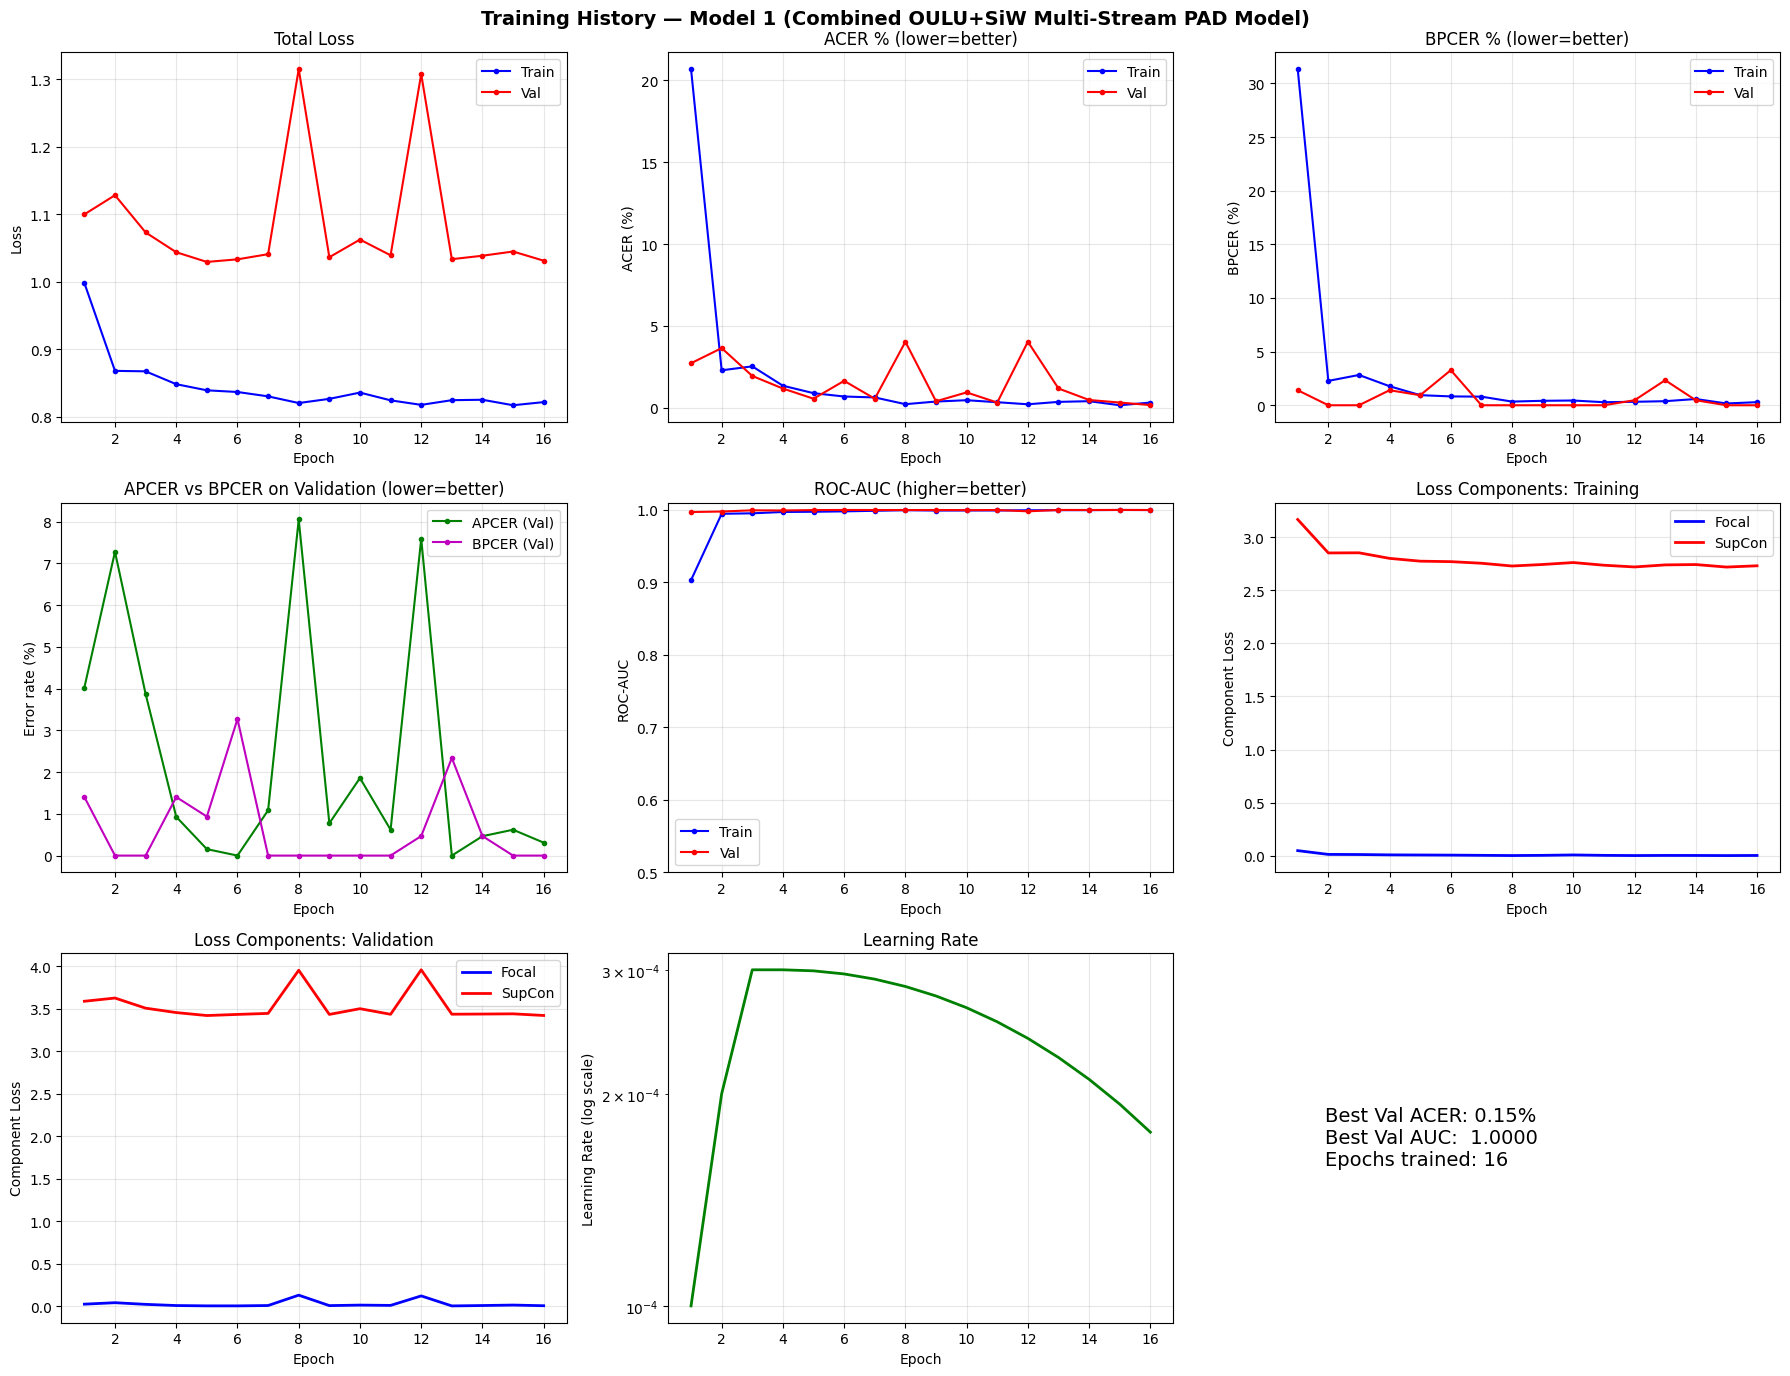

Training history plot saved to output_combinedData/model_1/training_history.png


In [25]:
# ============================================================================
#  STEP 8 — plot training history (loads history from saved checkpoint)
# ============================================================================
from Functions.run_epochs_17 import *

# ---- Load the saved checkpoint to recover `history` (training cell not run) ----
# The training checkpoint saved in Step 7c contains the full history dict.
checkpoint = torch.load(COMBINED_CKPT, map_location='cpu')
history = checkpoint['history']

# ---- Model 1 ----
plot_training_history(
    history,
    title='Training History — Model 1 (Combined OULU+SiW Multi-Stream PAD Model)',
    save_path=COMBINED_RESULT_DIR / 'training_history.png',
)

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

In [26]:
# ============================================================================
#  STEP 9 — form the held-out test set (Dataset + DataLoader)
# ============================================================================
#  held_out_test_df was built in Step 2, BEFORE Step 3's dataset-tagging
#  logic existed — so it has no 'dataset' or 'cache_dir' column yet, which
#  the (now-patched) PADVideoDataset needs per row. Add those here, then
#  build the actual Dataset/DataLoader — this is the "form the test set"
#  step that has to happen before evaluation can run.
# ============================================================================

# ---- tag held_out_test_df with 'dataset' and 'cache_dir', same logic as Step 3 ----
held_out_test_df = held_out_test_df.copy()
held_out_test_df['dataset'] = np.where(held_out_test_df['path'].isin(df_oulu['path']), 'OULU', 'SiW')
cache_dir_map = {'OULU': CACHE_DIR_OULU, 'SiW': CACHE_DIR_SiW}
held_out_test_df['cache_dir'] = held_out_test_df['dataset'].map(cache_dir_map)

print(f"Held-out test set: {len(held_out_test_df):,} videos "
      f"(OULU {(held_out_test_df['dataset']=='OULU').sum():,} | "
      f"SiW {(held_out_test_df['dataset']=='SiW').sum():,})")
print(f"  real {(held_out_test_df['label']==0).sum():,} | fake {(held_out_test_df['label']==1).sum():,}")

# ---- build the Dataset (single object, per-row cache_dir handles both roots) ----
held_out_test_dataset = PADVideoDataset(held_out_test_df, real_dir=REAL_DIR_OULU, cache_dir=CACHE_DIR_OULU,
                                        transform=val_transforms, demo_mode=False,
                                        use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)

held_out_test_loader = DataLoader(held_out_test_dataset, batch_size=CFG.BATCH_SIZE, shuffle=False,
                                  num_workers=0, pin_memory=True)   # num_workers=0, same CUDA-in-worker safety as Step 6

print(f"\nheld_out_test_loader ready: {len(held_out_test_dataset):,} videos, sequential")

Held-out test set: 844 videos (OULU 746 | SiW 98)
  real 150 | fake 694

held_out_test_loader ready: 844 videos, sequential


In [27]:
# =================== Load best combined model and evaluate on the HELD-OUT TEST set ===================
# Loads the best checkpoint saved during combined training, runs ONE pass
# over combined_val_loader to find the optimal threshold, then evaluates
# on held_out_test_loader (phone 6 + replay — guaranteed unseen by this
# model) and reports the final metrics at that threshold.
# --- 1. Load the best checkpoint (if it exists) -------------------------------
if COMBINED_CKPT.exists():
    # Read the checkpoint file onto the current device
    ckpt = torch.load(COMBINED_CKPT, map_location=DEVICE, weights_only=False)
    # Restore the model's trained weights
    model.load_state_dict(ckpt['state_dict'])
    # The print confirms which epoch's model loaded.
    print(f'Loaded best checkpoint (epoch {ckpt["epoch"]}, val ACER={ckpt["val_acer"]:.4f})')
else:
    # No checkpoint -> warn, but still evaluate whatever is currently in `model`
    print('[WARNING] No best checkpoint found; evaluating current in-memory model.')
# --- 2. Run one evaluation pass over the COMBINED validation set --------------
# is_train=False -> no weight updates, no gradients (pure evaluation).
# scaler=None    -> plain FP32 inference.
# take the loss, metrics, the predicted probabilities (val_probs) and (val_labels);
# ignore the loss-component dict (using _)
# Take the attacks types for further anyalysis later
val_loss, val_metrics, val_probs, val_labels, _, _ = run_epoch(
    model, combined_val_loader, optimizer, criterion, DEVICE, scaler=None, is_train=False)
# --- 3. Find the threshold that minimises ACER --------------------------------
# The model outputs probabilities (0–1), but we need a cut-off to decide real vs. fake.
# Instead of assuming 0.5, this step tries 100 thresholds from 0.1 to 0.9, computes ACER at each,
# and picks the one with the lowest ACER (np.argmin finds the index of the minimum).
# This finds the optimal decision boundary for the model.
val_labels_int = val_labels.round().astype(int)                                                 # ensure integer labels
thresholds = np.linspace(0.1, 0.9, 100)                                                         # 100 candidate cut-offs
val_acers = [compute_pad_metrics(val_labels_int, val_probs, t)['ACER'] for t in thresholds]
best_thresh = thresholds[np.argmin(val_acers)]                                                  # threshold with lowest ACER
# --- 4. Compute final metrics at the chosen threshold, on the HELD-OUT TEST set ----
# Run test pass
test_loss, test_metrics, test_probs, test_labels, _, test_attacks = run_epoch(
    model, held_out_test_loader, optimizer, criterion, DEVICE, scaler=None, is_train=False)
test_labels_int = test_labels.round().astype(int)
opt_metrics = compute_pad_metrics(test_labels_int, test_probs, threshold=best_thresh)
tdr = compute_tdr_at_fdr(test_labels_int, test_probs, target_fdr=0.01)   # already returns 0-100, no *100 needed
# --- 5. Report ----------------------------------------------------------------
# Print each metric as a percentage, labeled with whether higher or lower is better
print(f'\nOptimal Threshold = {best_thresh:.3f}')
print('=' * 50)
print('HELD-OUT TEST (phone 6 + replay — guaranteed unseen by this model)')
print('-' * 50)
for k, v in opt_metrics.items():
    # Label each metric with its "good" direction for readability
    direction = 'lower=better' if k in ['APCER', 'BPCER', 'ACER'] else 'higher=better'
    print(f'  {k:8s}: {v*100:.2f}%  ({direction})')
print(f'  TDR@1%  : {tdr:.2f}%  (higher=better)')
# --- 6. Save results to THIS model version's result folder --------------------
result_dir = COMBINED_RESULT_DIR
result_dir.mkdir(parents=True, exist_ok=True)
# Save the metrics as JSON
results_to_save = {
    'evaluation': 'held_out_test (phone 6 + replay)',
    'best_threshold': float(best_thresh),
    'test_metrics': {**{k: float(v) for k, v in opt_metrics.items()}, 'TDR': float(tdr)},
    'checkpoint_epoch': int(ckpt['epoch']) if COMBINED_CKPT.exists() else None,
    'n_test_videos': int(len(held_out_test_df)),
    'n_test_real': int((held_out_test_df['label']==0).sum()),
    'n_test_fake': int((held_out_test_df['label']==1).sum()),
}
with open(result_dir / 'held_out_test_metrics.json', 'w') as f:
    json.dump(results_to_save, f, indent=2)
print(f'\nResults saved to {result_dir / "held_out_test_metrics.json"}')

Loaded best checkpoint (epoch 16, val ACER=0.0015)



Optimal Threshold = 0.165
HELD-OUT TEST (phone 6 + replay — guaranteed unseen by this model)
--------------------------------------------------
  APCER   : 2.16%  (lower=better)
  BPCER   : 9.33%  (lower=better)
  ACER    : 5.75%  (lower=better)
  Acc     : 96.56%  (higher=better)
  AUC     : 98.82%  (higher=better)
  TDR@1%  : 90.35%  (higher=better)

Results saved to output_combinedData/model_1/held_out_test_metrics.json


In [28]:
# ============================================================================
#  HELD-OUT TEST — Per-Attack ACER + TDR table (paper format)
# ----------------------------------------------------------------------------
#  Reuses the test predictions from Step 10 (held-out test evaluation):
#  test_probs / test_labels / test_attacks / best_thresh.
#  Also needs compute_tdr_at_fdr() and the (fixed) metric defs.
#
#  Why ACER is computed this way:
#    ACER needs APCER (a SPOOF error) and BPCER (a REAL error). But "real"
#    faces are not attack-specific, so there is no per-attack BPCER. Following
#    the paper, each attack's ACER pairs THAT attack's APCER with the ONE
#    shared overall BPCER:  per-attack ACER = (attack APCER + overall BPCER)/2
#
#  NOTE ON THIS BEING A MIXED-DATASET TEST SET: held_out_test_df pools OULU's
#  phone-6 videos (any attack type present on that phone) with SiW's replay
#  videos — so the 'replay' row below combines BOTH datasets' replay clips.
#  A separate per-dataset breakdown is added at the end to check whether
#  OULU's and SiW's replay attacks actually behave similarly once pooled,
#  rather than assuming it.
# ============================================================================

# ---- Pull predictions into plain arrays (aligned per test sample) ----------
probs   = np.asarray(test_probs)                       # spoof probability, 0..1
labels  = np.asarray(test_labels).round().astype(int)  # ground truth: 0=real, 1=spoof
attacks = np.asarray(test_attacks)                     # attack-type string per sample
preds   = (probs >= best_thresh).astype(int)           # hard decision at the chosen threshold

# Strings that mean "real / bona-fide" in the attack_type column
REAL_NAMES = {'real', 'live', 'Real', 'Live'}

# ---- Split every sample into real vs spoof --------------------------------
is_real    = np.isin(attacks, list(REAL_NAMES)) | (labels == 0)
real_mask  = is_real
spoof_mask = ~is_real

# ---- Overall BPCER (shared by every attack) -------------------------------
n_real        = real_mask.sum()
real_rejected = ((preds == 1) & real_mask).sum()
overall_bpcer = real_rejected / (n_real + 1e-8)

real_probs  = probs[real_mask]
real_labels = labels[real_mask]

# ---- Per-attack metrics ----------------------------------------------------
rows = []
spoof_attack_names = sorted(set(attacks[spoof_mask].tolist()))

for atk in spoof_attack_names:
    m = (attacks == atk) & spoof_mask
    n_atk = m.sum()
    if n_atk == 0:
        continue

    atk_passed = ((preds == 0) & m).sum()
    atk_apcer  = atk_passed / (n_atk + 1e-8)
    atk_acer   = (atk_apcer + overall_bpcer) / 2

    combo_probs  = np.concatenate([real_probs,  probs[m]])
    combo_labels = np.concatenate([real_labels, labels[m]])
    atk_tdr = compute_tdr_at_fdr(combo_labels, combo_probs, target_fdr=0.01)

    rows.append({'attack': atk, 'n': int(n_atk),
                 'APCER': atk_apcer * 100, 'ACER': atk_acer * 100, 'TDR': atk_tdr})

# ---- Overall row (all spoofs pooled together) -----------------------------
overall_apcer = ((preds == 0) & spoof_mask).sum() / (spoof_mask.sum() + 1e-8)
overall_acer  = (overall_apcer + overall_bpcer) / 2
overall_tdr   = compute_tdr_at_fdr(labels, probs, target_fdr=0.01)

# ---- Print the per-attack table --------------------------------------------
print(f"{'Attack':<24}{'n':>5}{'APCER%':>9}{'ACER%':>9}{'TDR@1%':>9}")
print('-' * 56)
for r in rows:
    print(f"{r['attack']:<24}{r['n']:>5}{r['APCER']:>9.2f}{r['ACER']:>9.2f}{r['TDR']:>9.2f}")
print('-' * 56)
print(f"{'OVERALL':<24}{spoof_mask.sum():>5}{overall_apcer*100:>9.2f}"
      f"{overall_acer*100:>9.2f}{overall_tdr:>9.2f}")
print(f"\nShared overall BPCER (real rejected): {overall_bpcer*100:.2f}%")

# ============================================================================
#  ADDITION — per-DATASET breakdown, since this test set mixes OULU + SiW
#  (checks whether pooling OULU's and SiW's replay clips together above
#   is actually hiding a difference between how the two behave)
# ============================================================================
test_dataset_labels = np.asarray(held_out_test_df['dataset'])   # same row order as test_probs/test_labels

print("\n" + "=" * 56)
print("Per-dataset breakdown (within this held-out test set)")
print("=" * 56)
print(f"{'Dataset':<10}{'n':>5}{'APCER%':>9}{'BPCER%':>9}{'ACER%':>9}{'TDR@1%':>9}")
print('-' * 51)

dataset_rows = []
for ds in ['OULU', 'SiW']:
    ds_mask = test_dataset_labels == ds
    if ds_mask.sum() == 0:
        continue
    ds_real_mask  = ds_mask & real_mask
    ds_spoof_mask = ds_mask & spoof_mask

    ds_bpcer = (((preds == 1) & ds_real_mask).sum() / (ds_real_mask.sum() + 1e-8)) if ds_real_mask.sum() else 0.0
    ds_apcer = (((preds == 0) & ds_spoof_mask).sum() / (ds_spoof_mask.sum() + 1e-8)) if ds_spoof_mask.sum() else 0.0
    ds_acer  = (ds_apcer + ds_bpcer) / 2
    ds_tdr   = compute_tdr_at_fdr(labels[ds_mask], probs[ds_mask], target_fdr=0.01) if ds_mask.sum() else 0.0

    dataset_rows.append({'dataset': ds, 'n': int(ds_mask.sum()),
                          'APCER': ds_apcer*100, 'BPCER': ds_bpcer*100,
                          'ACER': ds_acer*100, 'TDR': ds_tdr})
    print(f"{ds:<10}{ds_mask.sum():>5}{ds_apcer*100:>9.2f}{ds_bpcer*100:>9.2f}{ds_acer*100:>9.2f}{ds_tdr:>9.2f}")

# ---- Save for the final paper-format comparison table ----------------------
held_out_per_attack = {
    'per_attack': rows,
    'per_dataset': dataset_rows,
    'overall': {'APCER': overall_apcer * 100, 'BPCER': overall_bpcer * 100,
                'ACER': overall_acer * 100, 'TDR': overall_tdr},
}

result_dir = COMBINED_RESULT_DIR
result_dir.mkdir(parents=True, exist_ok=True)

with open(result_dir / 'held_out_test_per_attack_metrics.json', 'w') as f:
    json.dump(held_out_per_attack, f, indent=2)

print(f"\nSaved per-attack table to {result_dir / 'held_out_test_per_attack_metrics.json'}")

Attack                      n   APCER%    ACER%   TDR@1%
--------------------------------------------------------
presentation              508     0.00     4.67    99.61
replay                    186     8.06     8.70    65.05
--------------------------------------------------------
OVERALL                   694     2.16     5.75    90.35

Shared overall BPCER (real rejected): 9.33%

Per-dataset breakdown (within this held-out test set)
Dataset       n   APCER%   BPCER%    ACER%   TDR@1%
---------------------------------------------------
OULU        746     0.00     9.33     4.67    99.66
SiW          98    15.31     0.00     7.65     0.00

Saved per-attack table to output_combinedData/model_1/held_out_test_per_attack_metrics.json


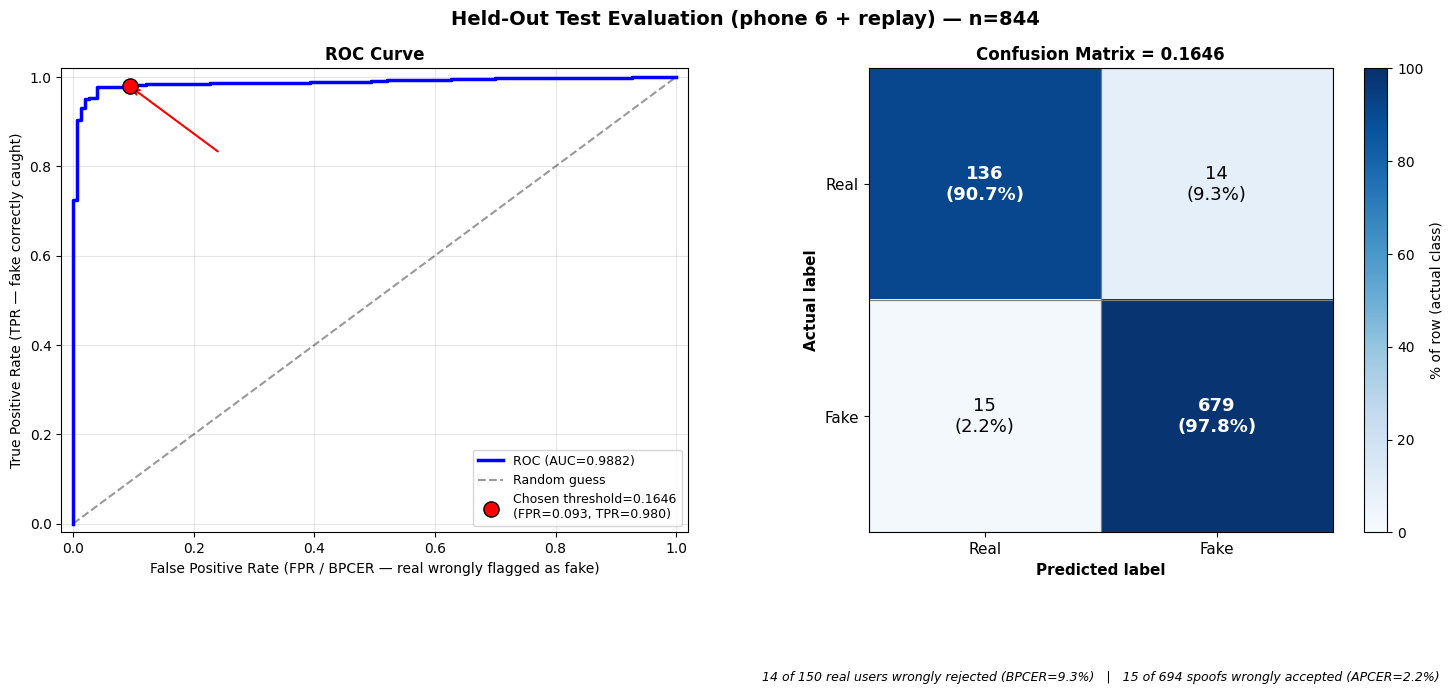

Saved to output_combinedData/model_1/roc_confusion_held_out_test.png


In [33]:
# ============== ROC + Confusion Matrix — HELD-OUT TEST ===================================
# Two diagnostic plots side by side from the held-out test predictions:
#   Left  : ROC curve (TPR vs FPR across thresholds) with the AUC score,
#           PLUS a marked point showing where the chosen threshold sits
#           on the curve (so ACER/APCER/BPCER's operating point is visible,
#           not just the threshold-independent AUC).
#   Right : Confusion matrix at the chosen threshold (counts + row-%),
#           with EXPLICIT actual-vs-predicted axis labels.
# Requires: from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

# Make sure this model version's result folder exists
result_dir = COMBINED_RESULT_DIR
result_dir.mkdir(parents=True, exist_ok=True)

y_true = test_labels.round().astype(int)
y_pred = (test_probs >= best_thresh).astype(int)
n_total = len(y_true)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
fig.suptitle(f'Held-Out Test Evaluation (phone 6 + replay) — n={n_total:,}',
             fontsize=14, fontweight='bold')

# ============================================================================
# LEFT — ROC curve, with the actual chosen operating point marked on it
# ============================================================================
fpr, tpr, roc_thresholds = roc_curve(y_true, test_probs)
auc_score = roc_auc_score(y_true, test_probs)

axes[0].plot(fpr, tpr, 'b-', lw=2.5, label=f'ROC (AUC={auc_score:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random guess')

# find and mark the point on the curve closest to the chosen threshold
op_idx = np.argmin(np.abs(roc_thresholds - best_thresh))
op_fpr, op_tpr = fpr[op_idx], tpr[op_idx]
axes[0].scatter([op_fpr], [op_tpr], s=120, color='red', zorder=5, edgecolor='black',
                label=f'Chosen threshold={best_thresh:.4f}\n(FPR={op_fpr:.3f}, TPR={op_tpr:.3f})')
axes[0].annotate('', xy=(op_fpr, op_tpr), xytext=(op_fpr + 0.15, op_tpr - 0.15),
                  arrowprops=dict(arrowstyle='->', color='red', lw=1.5))

axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(alpha=0.3)
axes[0].set_title('ROC Curve', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate (FPR / BPCER — real wrongly flagged as fake)')
axes[0].set_ylabel('True Positive Rate (TPR — fake correctly caught)')
axes[0].set_xlim(-0.02, 1.02); axes[0].set_ylim(-0.02, 1.02)

# ============================================================================
# RIGHT — Confusion matrix, with EXPLICIT actual-vs-predicted labeling
# ============================================================================
cm = confusion_matrix(y_true, y_pred)   # rows=ACTUAL, columns=PREDICTED (sklearn convention)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

im = axes[1].imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
cbar = plt.colorbar(im, ax=axes[1])
cbar.set_label('% of row (actual class)', fontsize=10)

axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(['Real', 'Fake'], fontsize=11)
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(['Real', 'Fake'], fontsize=11)
axes[1].set_xlabel('Predicted label', fontsize=11, fontweight='bold')   # columns = what the model predicted
axes[1].set_ylabel('Actual label', fontsize=11, fontweight='bold')      # rows = ground truth

for i in range(2):
    for j in range(2):
        # highlight the diagonal (correct predictions) vs off-diagonal (errors) with a border cue
        is_correct = (i == j)
        axes[1].text(
            j, i, f'{cm[i,j]:,}\n({cm_pct[i,j]:.1f}%)',
            ha='center', va='center',
            color='white' if cm_pct[i, j] > 50 else 'black',
            fontsize=13, fontweight='bold' if is_correct else 'normal'
        )
        # thin border box around every cell for readability
        axes[1].add_patch(plt.Rectangle((j-0.5, i-0.5), 1, 1, fill=False,
                                         edgecolor='gray', linewidth=0.8))

axes[1].set_title(f'Confusion Matrix = {best_thresh:.4f}', fontsize=12, fontweight='bold')

# small text box under the matrix summarizing error direction
n_real, n_fake = cm[0].sum(), cm[1].sum()
bpcer = cm[0, 1] / n_real * 100 if n_real else 0
apcer = cm[1, 0] / n_fake * 100 if n_fake else 0
axes[1].text(0.5, -0.32,
             f'{cm[0,1]} of {n_real} real users wrongly rejected (BPCER={bpcer:.1f}%)   |   '
             f'{cm[1,0]} of {n_fake} spoofs wrongly accepted (APCER={apcer:.1f}%)',
             transform=axes[1].transAxes, ha='center', fontsize=9, style='italic')

# Lay out, save, and display
plt.tight_layout()
save_path = result_dir / 'roc_confusion_held_out_test.png'
plt.savefig(save_path, dpi=140, bbox_inches='tight')
plt.show()

print(f'Saved to {save_path}')

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

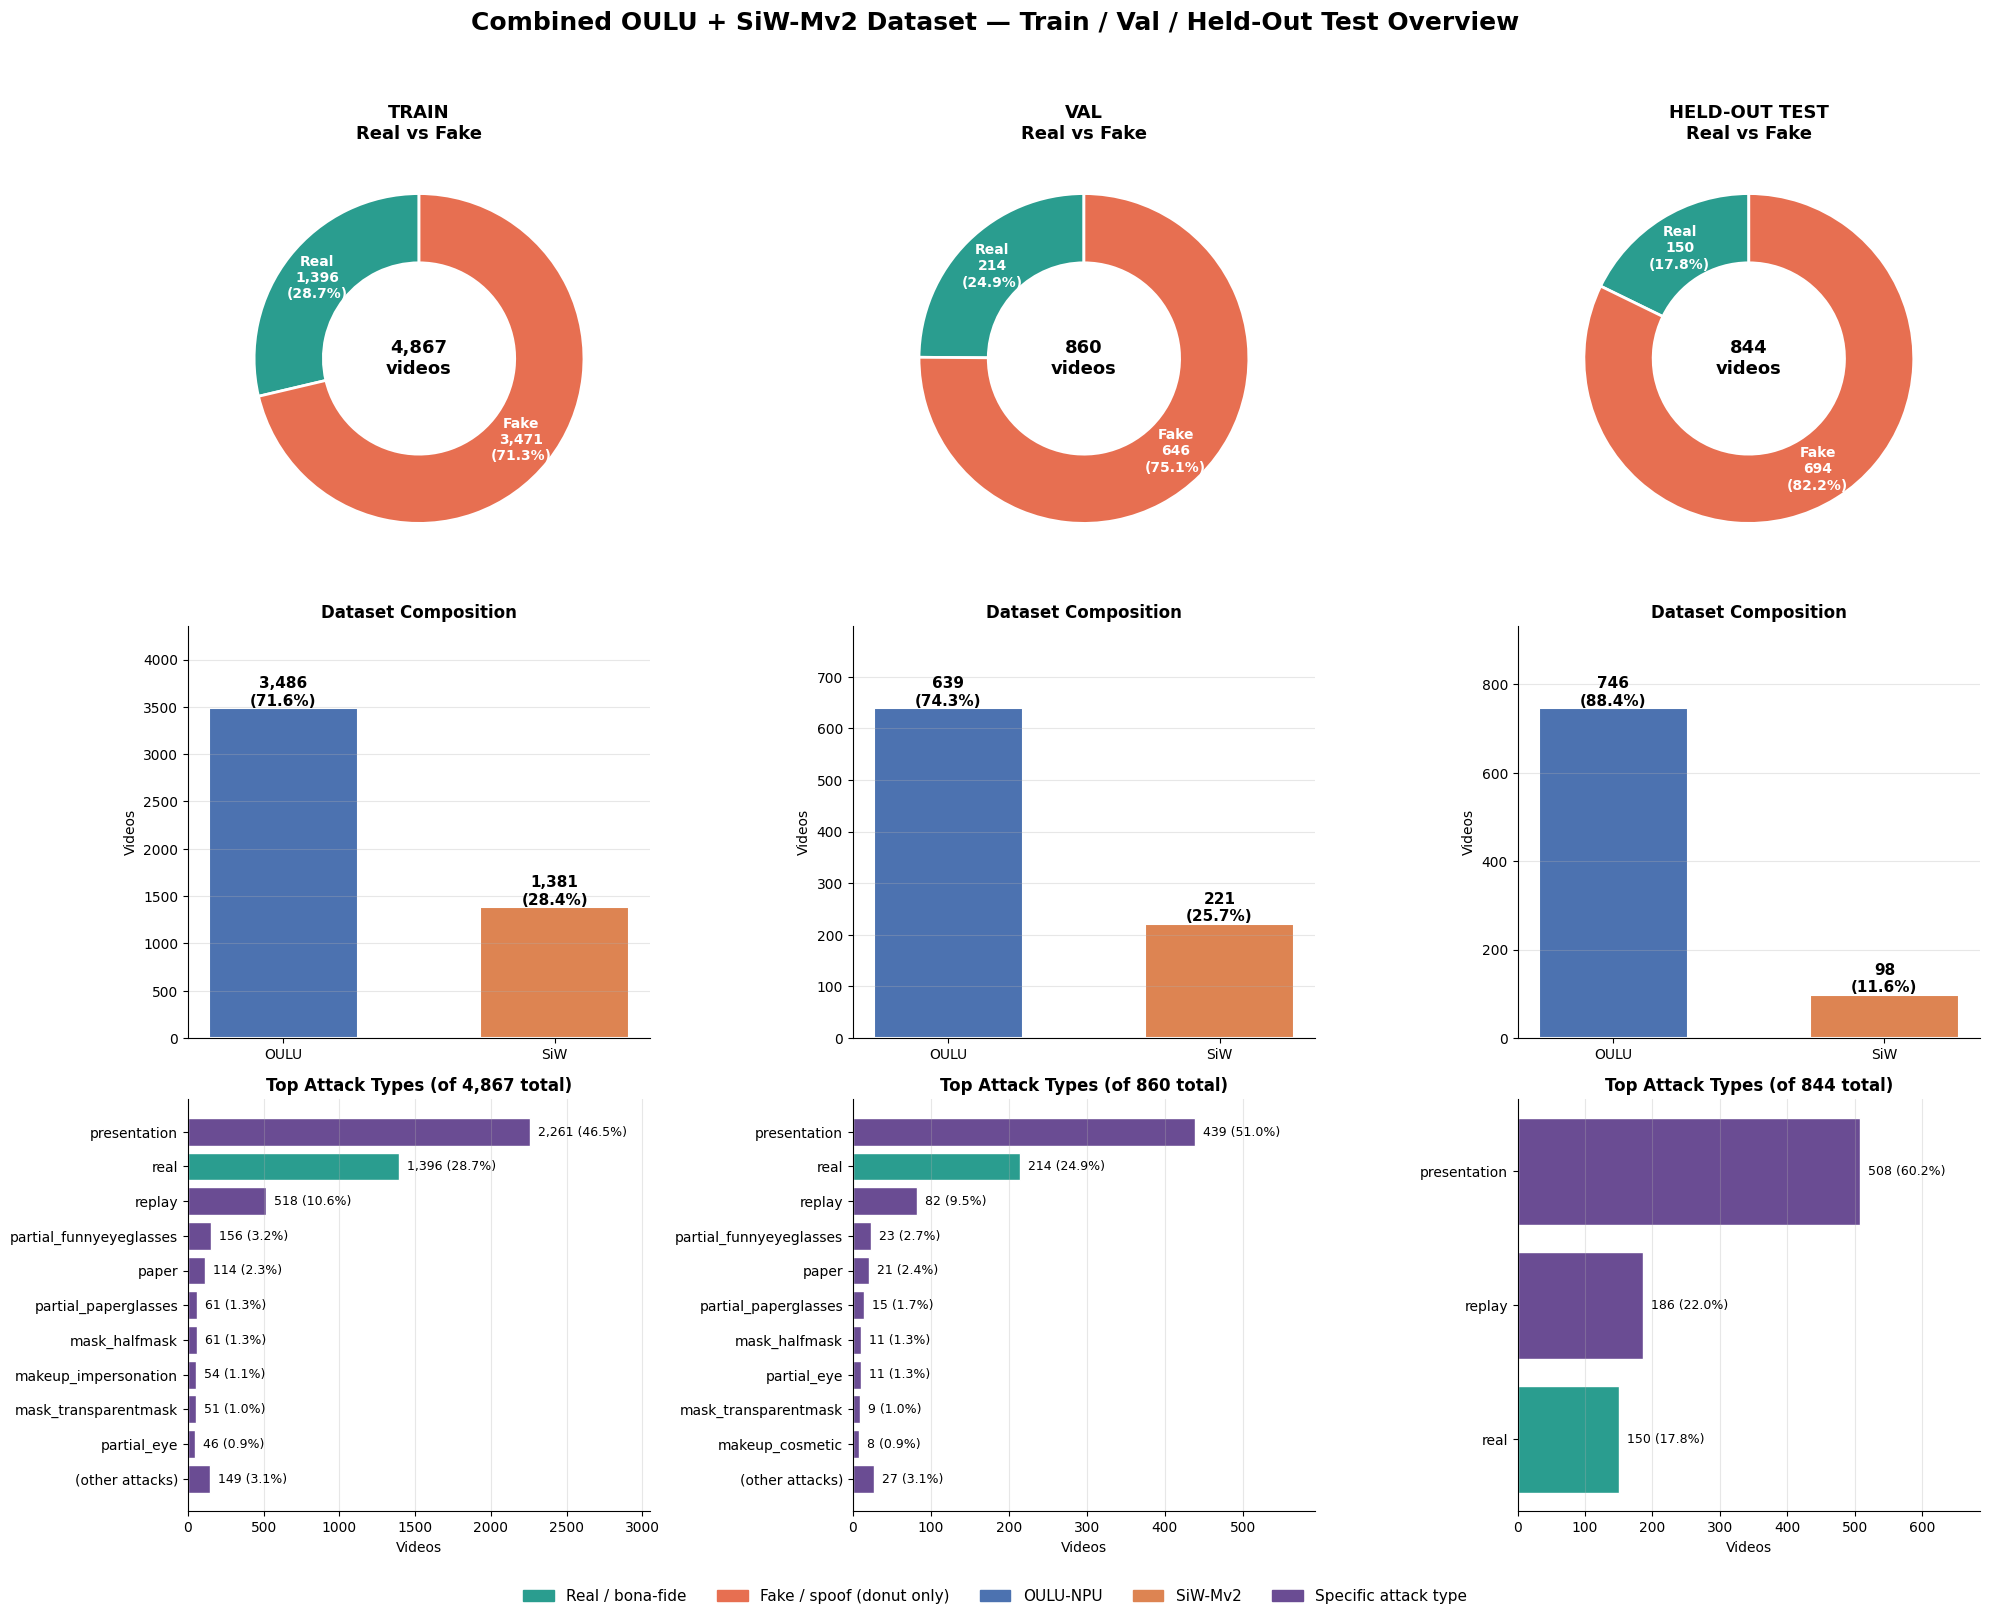

Dashboard saved to output_combinedData/model_1/dataset_overview_dashboard.png

SUMMARY TABLE
Split              Total    Real    Fake    OULU     SiW
--------------------------------------------------------
TRAIN              4,867   1,396   3,471   3,486   1,381
VAL                  860     214     646     639     221
HELD-OUT TEST        844     150     694     746      98


In [34]:
# ============================================================================
#  DATASET OVERVIEW DASHBOARD — Train / Val / Held-Out Test
# ============================================================================
#  One figure, 3 columns (Train, Val, Held-Out Test) x 3 rows:
#    Row 1: Real vs Fake donut chart
#    Row 2: OULU vs SiW composition bar chart
#    Row 3: Top attack types (horizontal bar, real included)
#  Every element is annotated with counts AND percentages directly on the
#  chart, not just in a legend — designed to stand alone in a report/slide.
# ============================================================================

# ---- consistent color palette across the whole dashboard ----
COLOR_REAL   = '#2a9d8f'   # teal
COLOR_FAKE   = '#e76f51'   # orange-red
COLOR_OULU   = '#4C72B0'   # blue
COLOR_SIW    = '#DD8452'   # orange
COLOR_ATTACK = '#6A4C93'   # purple, for attack-type bars

splits = {
    'TRAIN':          combined_train_df,
    'VAL':            combined_val_df,
    'HELD-OUT TEST':  held_out_test_df,
}

fig, axes = plt.subplots(3, 3, figsize=(20, 16))
fig.suptitle('Combined OULU + SiW-Mv2 Dataset — Train / Val / Held-Out Test Overview',
             fontsize=18, fontweight='bold', y=0.995)

for col, (split_name, df) in enumerate(splits.items()):

    n_total = len(df)
    n_real  = int((df['label'] == 0).sum())
    n_fake  = int((df['label'] == 1).sum())
    n_oulu  = int((df['dataset'] == 'OULU').sum())
    n_siw   = int((df['dataset'] == 'SiW').sum())

    # ========================================================================
    # ROW 0 — Real vs Fake donut chart
    # ========================================================================
    ax = axes[0, col]
    sizes  = [n_real, n_fake]
    colors = [COLOR_REAL, COLOR_FAKE]
    wedges, _ = ax.pie(sizes, colors=colors, startangle=90,
                        wedgeprops=dict(width=0.42, edgecolor='white', linewidth=2))
    # annotate each wedge with count + %
    for w, val, lbl in zip(wedges, sizes, ['Real', 'Fake']):
        ang = np.deg2rad((w.theta1 + w.theta2) / 2)
        x, y = 0.79 * np.cos(ang), 0.79 * np.sin(ang)
        pct = val / n_total * 100
        ax.text(x, y, f'{lbl}\n{val:,}\n({pct:.1f}%)', ha='center', va='center',
                fontsize=10, fontweight='bold', color='white')
    ax.text(0, 0, f'{n_total:,}\nvideos', ha='center', va='center',
            fontsize=13, fontweight='bold')
    ax.set_title(f'{split_name}\nReal vs Fake', fontsize=13, fontweight='bold', pad=10)

    # ========================================================================
    # ROW 1 — OULU vs SiW dataset composition
    # ========================================================================
    ax = axes[1, col]
    bars = ax.bar(['OULU', 'SiW'], [n_oulu, n_siw], color=[COLOR_OULU, COLOR_SIW], width=0.55,
                   edgecolor='white', linewidth=1.5)
    for b, val in zip(bars, [n_oulu, n_siw]):
        pct = val / n_total * 100
        ax.text(b.get_x() + b.get_width()/2, b.get_height(), f'{val:,}\n({pct:.1f}%)',
                ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax.set_title('Dataset Composition', fontsize=12, fontweight='bold')
    ax.set_ylabel('Videos')
    ax.set_ylim(0, max(n_oulu, n_siw) * 1.25)
    ax.grid(axis='y', alpha=0.3)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

    # ========================================================================
    # ROW 2 — top attack types (horizontal bar, includes 'real' as its own bucket)
    # ========================================================================
    ax = axes[2, col]
    df_plot = df.copy()
    df_plot['attack_display'] = np.where(df_plot['label'] == 0, 'real', df_plot['attack_type'])
    attack_counts = df_plot['attack_display'].value_counts().sort_values(ascending=True)
    TOP_N = 10
    if len(attack_counts) > TOP_N:
        top = attack_counts.tail(TOP_N)
        other_sum = attack_counts.iloc[:-TOP_N].sum()
        if other_sum > 0:
            top = pd.concat([pd.Series({'(other attacks)': other_sum}), top])
        attack_counts = top

    bar_colors = [COLOR_REAL if name == 'real' else COLOR_ATTACK for name in attack_counts.index]
    bars = ax.barh(attack_counts.index, attack_counts.values, color=bar_colors,
                    edgecolor='white', linewidth=1)
    for b, val in zip(bars, attack_counts.values):
        pct = val / n_total * 100
        ax.text(b.get_width(), b.get_y() + b.get_height()/2, f'  {val:,} ({pct:.1f}%)',
                ha='left', va='center', fontsize=9)
    ax.set_title(f'Top Attack Types (of {n_total:,} total)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Videos')
    ax.set_xlim(0, attack_counts.max() * 1.35)
    ax.grid(axis='x', alpha=0.3)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

# ---- shared legend at the bottom, explaining the color scheme once ----
legend_handles = [
    mpatches.Patch(color=COLOR_REAL, label='Real / bona-fide'),
    mpatches.Patch(color=COLOR_FAKE, label='Fake / spoof (donut only)'),
    mpatches.Patch(color=COLOR_OULU, label='OULU-NPU'),
    mpatches.Patch(color=COLOR_SIW, label='SiW-Mv2'),
    mpatches.Patch(color=COLOR_ATTACK, label='Specific attack type'),
]
fig.legend(handles=legend_handles, loc='lower center', ncol=5, fontsize=11,
           bbox_to_anchor=(0.5, -0.01), frameon=False)

plt.tight_layout(rect=[0, 0.02, 1, 0.97])

dashboard_path = COMBINED_RESULT_DIR / 'dataset_overview_dashboard.png'
plt.savefig(dashboard_path, dpi=150, bbox_inches='tight')
plt.show()

print(f'Dashboard saved to {dashboard_path}')

# ---- companion summary printout ----
print('\n' + '=' * 70)
print('SUMMARY TABLE')
print('=' * 70)
print(f"{'Split':<16}{'Total':>8}{'Real':>8}{'Fake':>8}{'OULU':>8}{'SiW':>8}")
print('-' * 56)
for split_name, df in splits.items():
    print(f"{split_name:<16}{len(df):>8,}{(df['label']==0).sum():>8,}{(df['label']==1).sum():>8,}"
          f"{(df['dataset']=='OULU').sum():>8,}{(df['dataset']=='SiW').sum():>8,}")

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

In [35]:
print(f"Current working directory: {os.getcwd()}")
print(f"COMBINED_RESULT_DIR (as currently defined): {COMBINED_RESULT_DIR}")
print(f"COMBINED_RESULT_DIR resolved to absolute:    {COMBINED_RESULT_DIR.resolve()}")
# print(f"COMBINED_CKPT (as currently defined):        {COMBINED_CKPT}")
print(f"MODEL_VERSION: {MODEL_VERSION}")

Current working directory: /storage/research/csdata_L/xp814142/MSc_Project
COMBINED_RESULT_DIR (as currently defined): output_combinedData/model_1
COMBINED_RESULT_DIR resolved to absolute:    /share/nas/cs-nas/xp814142/output_combinedData/model_1
MODEL_VERSION: model_1


In [36]:
# ============================================================================
#  LOAD CACHED PREDICTIONS IF THEY EXIST — otherwise run Step 10 to create them
# ============================================================================
#  First time this runs: no cache exists yet, so it falls through to running
#  Step 10's evaluation (inference only — NOT training, doesn't touch the
#  checkpoint) and SAVES the results as .npy files afterward.
#  Every time AFTER that (including after a kernel restart): loads directly
#  from disk in under a second — no inference needed at all.
# ============================================================================
 
CACHE_DIR_PREDICTIONS = COMBINED_RESULT_DIR / 'cached_predictions'
CACHE_DIR_PREDICTIONS.mkdir(parents=True, exist_ok=True)

cache_files = {
    'val_probs':    CACHE_DIR_PREDICTIONS / 'val_probs.npy',
    'val_labels':   CACHE_DIR_PREDICTIONS / 'val_labels.npy',
    'test_probs':   CACHE_DIR_PREDICTIONS / 'test_probs.npy',
    'test_labels':  CACHE_DIR_PREDICTIONS / 'test_labels.npy',
    'best_thresh':  CACHE_DIR_PREDICTIONS / 'best_thresh.npy',
}
 
if all(p.exists() for p in cache_files.values()):
    # ---- FAST PATH: load straight from disk, no inference at all ----
    val_probs   = np.load(cache_files['val_probs'])
    val_labels  = np.load(cache_files['val_labels'])
    test_probs  = np.load(cache_files['test_probs'])
    test_labels = np.load(cache_files['test_labels'])
    best_thresh = float(np.load(cache_files['best_thresh']))
    print(f"Loaded cached predictions from {CACHE_DIR_PREDICTIONS} — no inference run.")
    print(f"  val: {len(val_probs)} samples | test: {len(test_probs)} samples | threshold: {best_thresh:.4f}")
 
else:
    # ---- SLOW PATH (first time only): run Step 10's evaluation, then cache it ----
    print("No cache found — running evaluation once (inference only, not training)...")
 
    assert COMBINED_CKPT.exists(), f"No checkpoint found at {COMBINED_CKPT}"
    ckpt = torch.load(COMBINED_CKPT, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt['state_dict'])
    print(f'Loaded best checkpoint (epoch {ckpt["epoch"]}, val ACER={ckpt["val_acer"]:.4f})')
 
    val_loss, val_metrics, val_probs, val_labels, _, _ = run_epoch(
        model, combined_val_loader, optimizer, criterion, DEVICE, scaler=None, is_train=False)
 
    val_labels_int = val_labels.round().astype(int)
    thresholds = np.linspace(0.1, 0.9, 100)
    val_acers = [compute_pad_metrics(val_labels_int, val_probs, t)['ACER'] for t in thresholds]
    best_thresh = thresholds[np.argmin(val_acers)]
    print(f'Threshold (from val): {best_thresh:.4f}')
 
    test_loss, test_metrics, test_probs, test_labels, _, test_attacks = run_epoch(
        model, held_out_test_loader, optimizer, criterion, DEVICE, scaler=None, is_train=False)
 
    # ---- SAVE to disk, so any future kernel restart hits the fast path instead ----
    np.save(cache_files['val_probs'], val_probs)
    np.save(cache_files['val_labels'], val_labels)
    np.save(cache_files['test_probs'], test_probs)
    np.save(cache_files['test_labels'], test_labels)
    np.save(cache_files['best_thresh'], np.array(best_thresh))
    print(f"Predictions cached to {CACHE_DIR_PREDICTIONS} for instant reload next time.")
 
val_labels_int = val_labels.round().astype(int)   # needed by Part 1 Step 1 below either way

Loaded cached predictions from output_combinedData/model_1/cached_predictions — no inference run.
  val: 860 samples | test: 844 samples | threshold: 0.1646


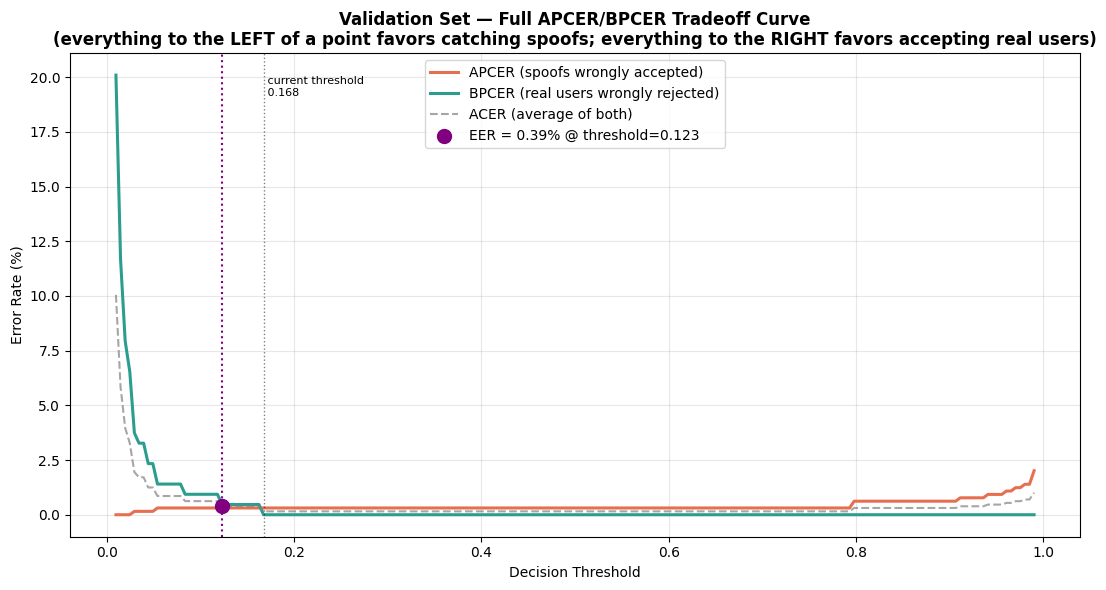

EER = 0.39%  at threshold = 0.1233
Current ACER-optimal threshold = 0.1676 (ACER = 0.15%)

Saved to output_combinedData/model_1/val_tradeoff_curve.png


In [37]:
# ============================================================================
#  PART 1, STEP 1 — APCER vs BPCER tradeoff curve (full threshold sweep)
# ============================================================================
#  Computed on the VALIDATION set (val_probs, val_labels from Step 10) —
#  NOT the held-out test set. Threshold exploration/decisions always happen
#  on val; the held-out test set is reserved for one final, honest check
#  once a threshold strategy is actually chosen (Part 2).
#
#  This shows APCER and BPCER at EVERY threshold from 0.01 to 0.99, not
#  just the single ACER-optimal one — this is the actual tradeoff curve
#  to improve on. Where the two lines cross is the EER
#  (Equal Error Rate) — a standard, threshold-choice-independent number
#  for comparing model VERSIONS against each other later.
# ============================================================================

val_labels_int = val_labels.round().astype(int)

# ---- sweep a FINE-grained set of thresholds (finer than the 100-step search) ----
thresholds_fine = np.linspace(0.01, 0.99, 200)

apcer_curve = []
bpcer_curve = []
acer_curve  = []

for t in thresholds_fine:
    m = compute_pad_metrics(val_labels_int, val_probs, t)
    apcer_curve.append(m['APCER'] * 100)
    bpcer_curve.append(m['BPCER'] * 100)
    acer_curve.append(m['ACER'] * 100)

apcer_curve = np.array(apcer_curve)
bpcer_curve = np.array(bpcer_curve)
acer_curve  = np.array(acer_curve)

# ---- find the EER: where APCER and BPCER curves cross (are closest to equal) ----
diff = np.abs(apcer_curve - bpcer_curve)
eer_idx = np.argmin(diff)
eer_thresh = thresholds_fine[eer_idx]
eer_value  = (apcer_curve[eer_idx] + bpcer_curve[eer_idx]) / 2

# ---- also mark where the current ACER-optimal threshold sits, for comparison ----
acer_opt_idx = np.argmin(acer_curve)
acer_opt_thresh = thresholds_fine[acer_opt_idx]

# ---- plot ----
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(thresholds_fine, apcer_curve, color='#e76f51', lw=2.2, label='APCER (spoofs wrongly accepted)')
ax.plot(thresholds_fine, bpcer_curve, color='#2a9d8f', lw=2.2, label='BPCER (real users wrongly rejected)')
ax.plot(thresholds_fine, acer_curve, color='gray', lw=1.5, ls='--', alpha=0.7, label='ACER (average of both)')

ax.axvline(eer_thresh, color='purple', lw=1.5, ls=':')
ax.scatter([eer_thresh], [eer_value], color='purple', s=100, zorder=5,
           label=f'EER = {eer_value:.2f}% @ threshold={eer_thresh:.3f}')

ax.axvline(acer_opt_thresh, color='black', lw=1, ls=':', alpha=0.5)
ax.text(acer_opt_thresh, ax.get_ylim()[1]*0.95, f' current threshold\n {acer_opt_thresh:.3f}',
        fontsize=8, va='top')

ax.set_xlabel('Decision Threshold')
ax.set_ylabel('Error Rate (%)')
ax.set_title('Validation Set — Full APCER/BPCER Tradeoff Curve\n'
              '(everything to the LEFT of a point favors catching spoofs; '
              'everything to the RIGHT favors accepting real users)',
              fontsize=12, fontweight='bold')
ax.legend(loc='upper center', fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()

tradeoff_path = COMBINED_RESULT_DIR / 'val_tradeoff_curve.png'
plt.savefig(tradeoff_path, dpi=140, bbox_inches='tight')
plt.show()

print(f'EER = {eer_value:.2f}%  at threshold = {eer_thresh:.4f}')
print(f'Current ACER-optimal threshold = {acer_opt_thresh:.4f} (ACER = {acer_curve[acer_opt_idx]:.2f}%)')
print(f'\nSaved to {tradeoff_path}')